# Summative Lab – Analytics Firm Clients: Customer Reviews Analysis

This notebook is a **starter notebook** for the three parts of the lab:

1. NLP  
2. Time Series  
3. Neural Networks  

Use the comments and TODO prompts to guide your work. The notebook is intentionally incomplete so you can implement the analysis yourself.


## Part 1: NLP

In this section, you will clean and preprocess review text, explore frequent words and bigrams, and visualize key language patterns in the dataset.


In [134]:
# =========================
# Part 1: NLP Starter Code
# =========================

# TODO: Import the libraries you need for:
# - data handling
# - plotting
# - text preprocessing
# - tokenization / stopwords / lemmatization
# - counting words and bigrams

# Example:
# import pandas as pd

# TODO: Download any required NLTK resources.

# TODO: Load the dataset.
# Hint: The file used in this lab is 'amazon_reviews_lab.csv'
# df = ...

# TODO: Explore the dataset.
# Suggested checks:
# - shape
# - value counts for the rating column
# - preview the first few rows

# TODO: Create preprocessing tools such as:
# - stop_words
# - lemmatizer

# TODO: Write a function called preprocess_text(text) that:
# 1. converts text to lowercase
# 2. removes URLs
# 3. removes punctuation
# 4. tokenizes the text
# 5. keeps alphabetic tokens only
# 6. removes stopwords
# 7. lemmatizes the remaining tokens
# 8. returns the cleaned tokens

# def preprocess_text(text):
#     pass

# TODO: Apply your preprocessing function to the review text column
# and store the output in a new column such as 'processed_tokens'.

# TODO: Combine all tokens into one list so you can compute word frequencies.

# TODO: Use Counter to identify the most common words.

# TODO: Generate bigrams from the token list and identify the most common bigrams.

# TODO: Create at least one visualization of the most common words.
# You may also choose to visualize the most common bigrams.

# Reflection prompt:
# What do the most common words or phrases suggest about customer sentiment or product experience?


In [127]:
import re
import string
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, itertools

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from nltk.util import bigrams, trigrams
from nltk.collocations import BigramCollocationFinder, BigramAssocMeasures



for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

sns.set_theme(style="whitegrid")

In [2]:
# load dataset
df = pd.read_csv("amazon_reviews_lab.csv")

In [3]:
df.shape

(997, 9)

In [4]:
df.head()


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 997 entries, 0 to 996
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           997 non-null    object 
 1   rating               997 non-null    int64  
 2   review_text          997 non-null    object 
 3   review_summary       997 non-null    object 
 4   review_time_raw      997 non-null    object 
 5   unix_review_time     997 non-null    float64
 6   timestamp            997 non-null    object 
 7   sentiment_label      997 non-null    object 
 8   review_length_words  997 non-null    int64  
dtypes: float64(1), int64(2), object(6)
memory usage: 70.2+ KB


In [6]:
df. describe()

,rating,unix_review_time,review_length_words
count,997.000000,9.970000e+02,997.000000
mean,4.129388,1.344766e+09,146.374122
std,1.280181,4.411420e+07,216.126770
min,1.000000,9.580896e+08,5.000000
25%,4.000000,1.311898e+09,32.000000
50%,5.000000,1.356048e+09,67.000000
75%,5.000000,1.379462e+09,165.000000
max,5.000000,1.405555e+09,2079.000000


In [7]:
df.isnull().sum()

product_id             0
rating                 0
review_text            0
review_summary         0
review_time_raw        0
unix_review_time       0
timestamp              0
sentiment_label        0
review_length_words    0
dtype: int64

In [8]:
 df["rating"].value_counts().sort_index()

rating
1     87
2     48
3     94
4    188
5    580
Name: count, dtype: int64

### Dataset Exploration

- **Size:** 997 reviews, 9 columns, no missing values.
- **Ratings:** mean 4.13, median 5. Strongly skewed positive.

| Rating | Count | Share |
|---|---|---|
| 1 | 87 | 8.7% |
| 2 | 48 | 4.8% |
| 3 | 94 | 9.4% |
| 4 | 188 | 18.9% |
| 5 | 580 | 58.2% |

- **Review length:** median 67 words, mean 146, max 2,079. A few very long reviews pull the mean up.
- **Dates:** `unix_review_time` runs from 2000 to 2014. The `timestamp` column is still a string and needs converting to datetime
- **Implication:** the classes are imbalanced. Accuracy alone would be misleading in 

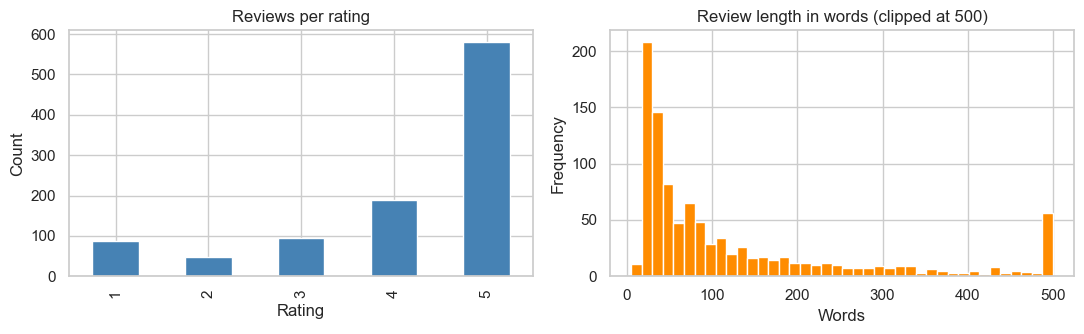

In [9]:
# Class balance + review length: 
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df["rating"].value_counts().sort_index().plot(kind="bar", ax=ax[0], color="steelblue")
ax[0].set_title("Reviews per rating"); ax[0].set_xlabel("Rating"); ax[0].set_ylabel("Count")
df["review_length_words"].clip(upper=500).plot(kind="hist", bins=40, ax=ax[1], color="darkorange")
ax[1].set_title("Review length in words (clipped at 500)"); ax[1].set_xlabel("Words")
plt.tight_layout(); plt.show()

### Rating and Review Length Plots

- **Reviews per rating:** 5-star reviews dominate (580), followed by 4-star (190). Ratings 1, 2 and 3 each have fewer than 100 reviews. The data is heavily skewed positive.
- **Review length:** most reviews are short, with a peak around 20-40 words and a long right tail. The bar at 500 is the clipped bucket, holding about 55 reviews of 500+ words.
- **Implication:** the imbalance means the model could score well by mostly predicting 5 stars, 

In [10]:
# Preprocessing tools 
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

In [11]:
negations = {"no", "not", "nor", "never"}
stop_words = stop_words - negations


def preprocess_text(text):
    """Lowercase -> strip URLs/HTML -> strip punctuation -> tokenize ->
    alphabetic only -> remove stopwords -> lemmatize -> return list of tokens."""
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)          
    text = re.sub(r"<[^>]+>", " ", text)                   
    text = text.replace("'", "")                            
    text = text.translate(str.maketrans(string.punctuation, " " * len(string.punctuation)))
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t.isalpha()]             # alphabetic only
    tokens = [t for t in tokens if t not in stop_words]     # stopwords
    tokens = [t for t in tokens if len(t) > 2]              # drop leftover 1-2 letter fragments
    tokens = [lemmatizer.lemmatize(t) for t in tokens]      # lemmatize
    return tokens


# Validate on one example before applying to everything
example = df["review_text"].iloc[0]
print("BEFORE:", example[:300])
print("AFTER :", preprocess_text(example)[:40])

BEFORE: This film is definitely not for anyone who is especially fond of the independent, delightfully manipulative and clever boy who was the brain child of Samuel Clemens's classic.As one example, the book has great fun with the scenes involving Aunt Polly, a simple minded soul who thinks herself quite cl
AFTER : ['film', 'definitely', 'not', 'anyone', 'especially', 'fond', 'independent', 'delightfully', 'manipulative', 'clever', 'boy', 'brain', 'child', 'samuel', 'clemens', 'classic', 'one', 'example', 'book', 'great', 'fun', 'scene', 'involving', 'aunt', 'polly', 'simple', 'minded', 'soul', 'think', 'quite', 'clever', 'genuinely', 'shrewd', 'tom', 'play', 'catering', 'pollys', 'illusion', 'wit', 'far']


### Preprocessing Check

- **Cleaning worked:** text is lowercase with punctuation and stopwords removed ("this", "is", "for", "who").
- **Negation kept:** "not" stays in the tokens, so "not for anyone" is not read as positive.
- **Lemmatization:** plurals and verb forms are reduced ("scenes" → "scene", "thinks" → "think").
- **Known quirk:** removing apostrophes turns "Polly's" into "pollys". This is minor and doesn't affect the analysis.
- **Result:** the review shrank from about 60 words to about 40 meaningful tokens.

In [12]:
#Apply to the dataset
df["processed_tokens"] = df["review_text"].apply(preprocess_text)
df["clean_len"] = df["processed_tokens"].apply(len)

print("Average tokens per review: raw =", round(df["review_length_words"].mean(), 1),
      "| cleaned =", round(df["clean_len"].mean(), 1))
print("Reviews left with 0 tokens:", (df["clean_len"] == 0).sum())

Average tokens per review: raw = 146.4 | cleaned = 72.5
Reviews left with 0 tokens: 0


In [13]:
# Combine all tokens, count words 
all_tokens = [tok for tokens in df["processed_tokens"] for tok in tokens]
word_freq = Counter(all_tokens)
print("\nVocabulary size:", len(word_freq))
print("Top 20 words:", word_freq.most_common(20))


Vocabulary size: 6518
Top 20 words: [('nook', 1577), ('not', 1064), ('book', 986), ('one', 596), ('kindle', 584), ('screen', 535), ('like', 474), ('read', 464), ('work', 462), ('great', 444), ('tablet', 443), ('use', 432), ('get', 426), ('device', 399), ('would', 380), ('good', 348), ('reader', 346), ('well', 341), ('time', 329), ('also', 329)]


In [14]:
# Bigrams and trigrams 
bigram_list = [bg for tokens in df["processed_tokens"] for bg in bigrams(tokens)]
trigram_list = [tg for tokens in df["processed_tokens"] for tg in trigrams(tokens)]
bigram_freq = Counter(bigram_list)
trigram_freq = Counter(trigram_list)

print("Top 15 bigrams:")
for bg, c in bigram_freq.most_common(15):
    print(f"  {' '.join(bg):<25}{c}")

print("\nTop 10 trigrams:")
for tg, c in trigram_freq.most_common(10):
    print(f"  {' '.join(tg):<30}{c}")

Top 15 bigrams:
  barnes noble             165
  nook color               135
  battery life             98
  touch screen             96
  nook tablet              66
  work great               65
  kindle fire              61
  work well                59
  read book                58
  wall mount               53
  simple touch             45
  customer service         41
  android tablet           41
  original nook            38
  nook simple              38

Top 10 trigrams:
  nook simple touch             37
  barnes noble nook             14
  barnes noble store            11
  adobe digital edition         10
  google play store             9
  book barnes noble             8
  access google play            8
  acer aspire one               7
  not big deal                  7
  access android market         7


### Word and Phrase Frequency

- **Preprocessing:** average tokens per review fell from 146.4 to 72.5. No review was left empty.
- **Vocabulary:** 6,518 unique words.
- **Top words:** "nook" (1,577) leads, then "not", "book", "kindle", "screen" and "tablet". The reviews are about e-readers and tablets, mainly the Nook.
- **Top bigrams:** "barnes noble" (165), "nook color" (135), "battery life" (98) and "touch screen" (96). Customers focus on the brand, specific models, battery and screen.
- **Positive phrases:** "work great" (65) and "work well" (59).
- **Pain points:** "customer service" (41) and "not big deal" (7) hint at support issues and mixed opinions.
- **Trigrams:** "nook simple touch" (37) is the most discussed model. "google play store" and "access android market" show users wanting to run Android apps.
- "not" is the second most common word, so negation matters for sentiment.

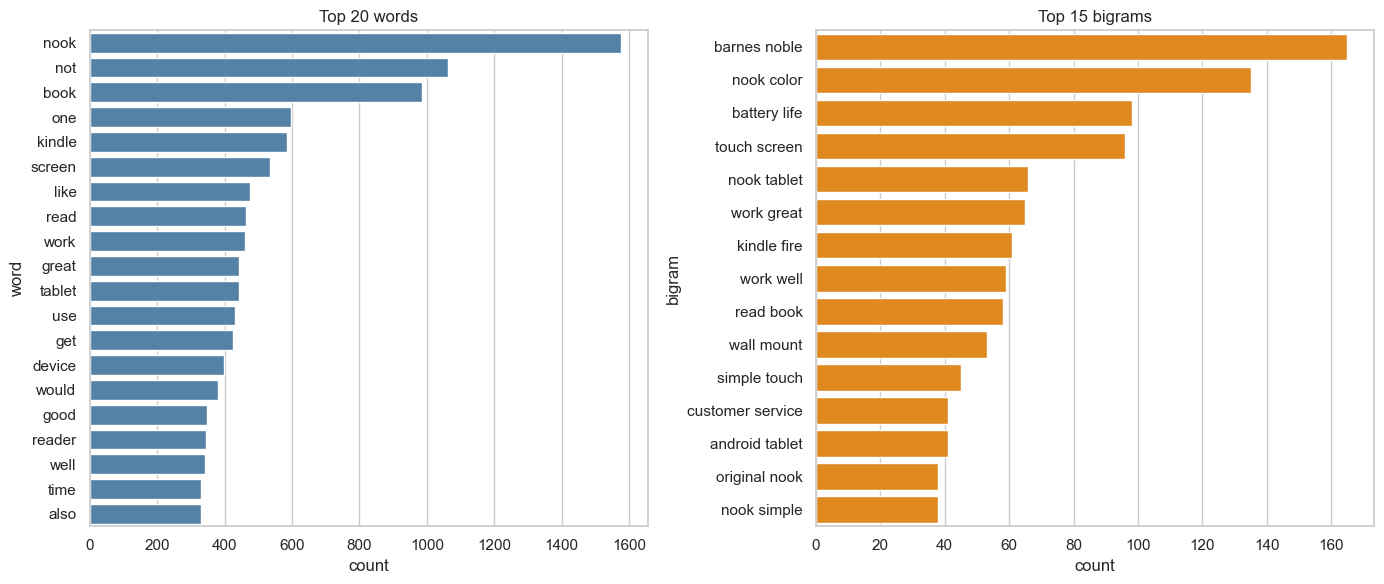

In [15]:
#  Visualizations: top words and top bigrams 
top_words = pd.DataFrame(word_freq.most_common(20), columns=["word", "count"])
top_bigrams = pd.DataFrame([(" ".join(b), c) for b, c in bigram_freq.most_common(15)],
                           columns=["bigram", "count"])

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=top_words, y="word", x="count", ax=ax[0], color="steelblue")
ax[0].set_title("Top 20 words")
sns.barplot(data=top_bigrams, y="bigram", x="count", ax=ax[1], color="darkorange")
ax[1].set_title("Top 15 bigrams")
plt.tight_layout(); plt.show()

### Top Words and Bigrams Charts

- **Top words:** "nook" is far ahead (1,580), followed by "not" (1,060) and "book" (990). Next come "kindle", "screen", "read" and "tablet", so the reviews focus on e-readers and tablets.
- **Top bigrams:** "barnes noble"

  (165) and "nook color" (135) lead. "battery life" (98) and "touch screen" (96) show the features people mention most.
- **Sentiment hints:** "work great" and "work well" are common, so many reviews are positive. "customer service" and the high count of "not" suggest some complaints too.
   the data is mostly about Barnes & Noble Nook devices, and battery, screen and ease of use matter most to customers.

In [132]:
#!pip install wordcloud

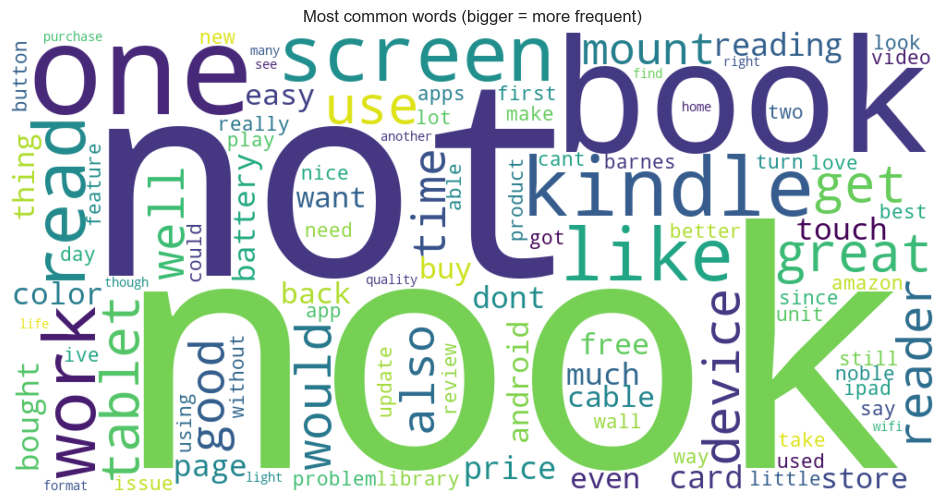

In [23]:

from wordcloud import WordCloud

wc = WordCloud(width=1000, height=500, background_color="white",
               max_words=100, colormap="viridis").generate_from_frequencies(word_freq)

plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Most common words (bigger = more frequent)")
plt.show()

**Word cloud:** the biggest words (nook, not, book, kindle, screen) are the most frequent. It confirms the reviews are mainly about Nook e-readers and tablets, and that negation ("not") is common.

In [18]:
def top_words_for(mask, n=15):
    c = Counter(tok for toks in df.loc[mask, "processed_tokens"] for tok in toks)
    return c

pos = top_words_for(df["rating"] >= 4)
neg = top_words_for(df["rating"] <= 2)

# Relative frequency (per 1,000 tokens) so the big positive group doesn't dominate
pos_total, neg_total = sum(pos.values()), sum(neg.values())
vocab = [w for w, c in (pos + neg).items() if c >= 15]
comp = pd.DataFrame({
    "pos_per_1k": [pos[w] / pos_total * 1000 for w in vocab],
    "neg_per_1k": [neg[w] / neg_total * 1000 for w in vocab],
}, index=vocab)
comp["diff"] = comp["pos_per_1k"] - comp["neg_per_1k"]

print("Words most associated with 4-5 star reviews:")
print(comp.sort_values("diff", ascending=False).head(12).round(2))
print("\nWords most associated with 1-2 star reviews:")
print(comp.sort_values("diff").head(12).round(2))

Words most associated with 4-5 star reviews:
         pos_per_1k  neg_per_1k  diff
great          7.94        1.82  6.12
nook          23.07       18.34  4.73
easy           4.54        0.91  3.63
kindle         8.68        5.53  3.15
love           3.92        0.77  3.15
price          4.95        1.82  3.13
mount          5.11        2.24  2.87
color          4.23        1.54  2.69
screen         7.63        5.18  2.45
good           5.54        3.43  2.11
reader         5.21        3.15  2.06
feature        2.54        0.63  1.91

Words most associated with 1-2 star reviews:
          pos_per_1k  neg_per_1k  diff
not            12.81       18.27 -5.47
customer        0.49        3.01 -2.52
even            2.67        5.18 -2.51
cant            1.40        3.64 -2.24
return          0.31        2.17 -1.86
service         0.57        2.38 -1.81
buy             3.30        4.90 -1.60
credit          0.16        1.68 -1.52
could           2.18        3.64 -1.46
time            4.35     

### Positive vs Negative Language

**4-5 star reviews** (rates per 1,000 words)
- Top words: "great" (7.9 vs 1.8 in negative reviews), "easy", "love", "price" and "feature". Happy customers praise ease of use, value and features.
- "Nook", "kindle", "color" and "screen" also lean positive, which mostly reflects the topic being discussed.

**1-2 star reviews**
- Top words: "not" (18.3 vs 12.8), "customer", "service", "return", "credit", "cant" and "even". Unhappy customers mention support problems, returns, refunds and things not working.
- "Update" and "case" also lean negative, which hints at software and accessory issues.

positive reviews talk about product strengths, while negative reviews talk about service, returns and failures. "Not" appears in both groups, so negation alone doesn't separate them.

In [18]:
finder = BigramCollocationFinder.from_documents(df["processed_tokens"])
finder.apply_freq_filter(8)                                   # ignore very rare pairs
pmi_pairs = finder.score_ngrams(BigramAssocMeasures.pmi)[:15]
display(pd.DataFrame([(" ".join(p), round(s, 2), finder.ngram_fd[p]) for p, s in pmi_pairs],
                     columns=["collocation", "PMI", "count"]))

,collocation,PMI,count
0,acer aspire,11.68,8
1,angry bird,11.56,19
2,answer question,10.68,8
3,operating system,10.48,15
4,eye strain,10.44,11
5,stud finder,10.39,8
6,virtual keyboard,10.37,11
7,heavy duty,10.35,9
8,truck specific,10.16,8
9,adobe digital,10.03,12


## PMI Collocations

High PMI scores (about 10–11) show these word pairs appear together far more than chance, so they are real phrases.

Devices: acer aspire, galaxy tab. Customers compare the Nook with other tablets.
Apps and software: angry bird, operating system, virtual keyboard.
Comfort: eye strain.
Opinions: deal breaker (negative), highly recommended (positive).
Off-topic: stud finder, truck specific. A few reviews are about unrelated products.

Takeaway: customers treat the Nook as a tablet, and apps and screen comfort are key topics.

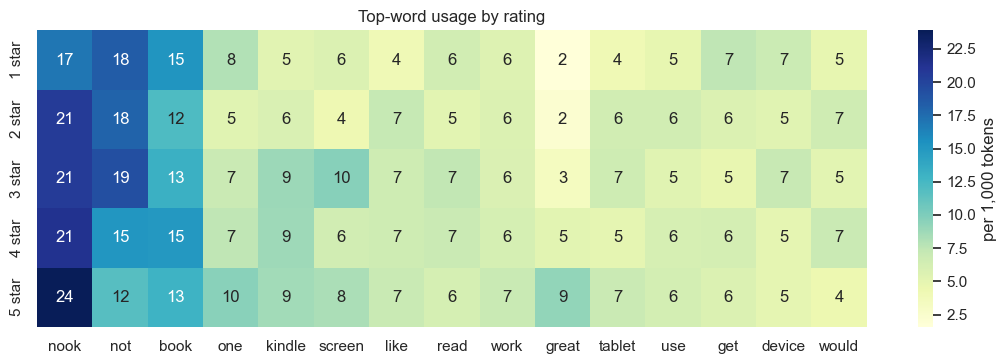

In [19]:
# Term distribution per rating: relative frequency (per 1,000 tokens) of the 15 most common words
top_terms = [w for w, _ in word_freq.most_common(15)]
rates = {}
for r, grp in df.groupby("rating"):
    c = Counter(t for toks in grp["processed_tokens"] for t in toks)
    total = sum(c.values())
    rates[f"{r} star"] = {w: c[w] / total * 1000 for w in top_terms}

plt.figure(figsize=(11, 3.8))
sns.heatmap(pd.DataFrame(rates).T, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "per 1,000 tokens"})
plt.title("Top-word usage by rating"); plt.tight_layout(); plt.show()

## Top-Word Usage by Rating
“not” falls as ratings rise: about 18–19 per 1,000 words in 1–3 star reviews, down to 12 in 5-star reviews. Unhappy customers use more negation.
“great” rises with rating: 2 in 1–2 star reviews, up to 9 in 5-star reviews.
“nook” is mentioned more in 5-star reviews (24) than in 1-star (17).
“book,” “work,” “device” stay about the same across all ratings, so they describe the topic, not the sentiment.

 “not” and “great” separate unhappy from happy reviews, while topic words like “book” and “device” do not.

Most associated with 4-5 star reviews:


,pos_per_1k,neg_per_1k,diff
great,7.94,1.82,6.12
nook,23.07,18.34,4.73
easy,4.54,0.91,3.63
kindle,8.68,5.53,3.15
love,3.92,0.77,3.15
price,4.95,1.82,3.13
mount,5.11,2.24,2.87
color,4.23,1.54,2.69
screen,7.63,5.18,2.45
good,5.54,3.43,2.11


Most associated with 1-2 star reviews:


,pos_per_1k,neg_per_1k,diff
not,12.81,18.27,-5.47
customer,0.49,3.01,-2.52
even,2.67,5.18,-2.51
cant,1.40,3.64,-2.24
return,0.31,2.17,-1.86
service,0.57,2.38,-1.81
buy,3.30,4.90,-1.60
credit,0.16,1.68,-1.52
could,2.18,3.64,-1.46
time,4.35,5.81,-1.46


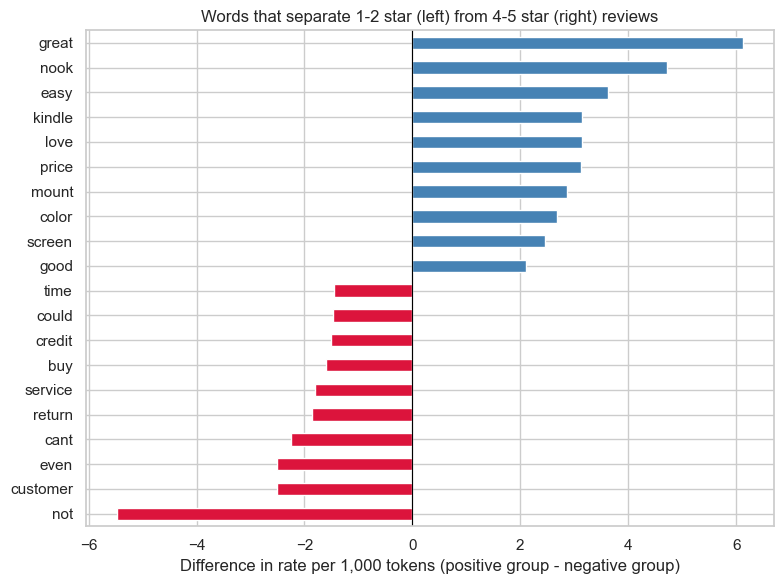

In [20]:
# Which words separate happy (4-5) from unhappy (1-2) reviews?
def count_words(mask):
    return Counter(t for toks in df.loc[mask, "processed_tokens"] for t in toks)

pos, neg = count_words(df["rating"] >= 4), count_words(df["rating"] <= 2)
pos_total, neg_total = sum(pos.values()), sum(neg.values())
vocab = [w for w in set(pos) | set(neg) if pos[w] + neg[w] >= 15]
comp = pd.DataFrame({"pos_per_1k": [pos[w] / pos_total * 1000 for w in vocab],
                     "neg_per_1k": [neg[w] / neg_total * 1000 for w in vocab]}, index=vocab)
comp["diff"] = comp["pos_per_1k"] - comp["neg_per_1k"]

top_pos = comp.sort_values("diff", ascending=False).head(10)
top_neg = comp.sort_values("diff").head(10)
print("Most associated with 4-5 star reviews:"); display(top_pos.round(2))
print("Most associated with 1-2 star reviews:"); display(top_neg.round(2))

fig, ax = plt.subplots(figsize=(8, 6))
diffs = pd.concat([top_neg["diff"], top_pos["diff"]]).sort_values()
diffs.plot(kind="barh", ax=ax, color=["crimson" if v < 0 else "steelblue" for v in diffs])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Words that separate 1-2 star (left) from 4-5 star (right) reviews")
ax.set_xlabel("Difference in rate per 1,000 tokens (positive group - negative group)")
plt.tight_layout(); plt.show()

## Happy vs Unhappy Words

## 4–5 star reviews (right, blue)

great, easy, love, good show customer satisfaction. “great” is the strongest signal.
price shows value for money is a plus.
nook, kindle, screen, color, mount lean positive mostly because they are the topic being discussed.

## 1–2 star reviews (left, red)

not, cant, even show frustration and things not working. “not” is the strongest negative signal.
customer, service, return, credit point to support problems, returns and refunds.
buy, time, could are weaker signals.

Takeaway: happy customers praise the product (ease, value), while unhappy customers complain about support and returns. Support should prioritise reviews mentioning service, returns and refunds.

### Part 1 Reflection

The top words and bigrams (“nook”, “kindle”, “barnes noble”, “nook color”, “battery life”, “touch screen”) show that customers are reviewing e-readers and tablets, mainly Barnes & Noble Nook devices. They care most about battery life, the screen and how well the device works for reading. Words like “great”, “easy”, “love” and “price” separate 4-5 star reviews from 1-2 star reviews, while “not”, “customer”, “service”, “return” and “credit” mark the unhappy ones, which points to support and refund problems. I was not surprised that “customer service” and “return” appear in negative reviews, but I was surprised that “not” is common in both groups (12.8 vs 18.3 per 1,000 words), so it is a signal but cannot separate them alone. I kept negations like “not” because removing them would change the meaning of phrases like “not good”. Stopword removal and lemmatization cut the average tokens per review from 146.4 to 72.5 and left a vocabulary of 6,518 unique words. The main limitation is that bag-of-words loses word order, so “not good” is counted as separate words “not” and “good”, and “good” alone leans positive. Bigrams help a little, but they still miss longer context.

## Part 2: Time Series

In this section, you will analyze review activity over time by converting timestamps, resampling the data, and visualizing trends in review volume and ratings.


In [133]:
# ==============================
# Part 2: Time Series Starter Code
# ==============================

# TODO: Import the libraries you need.

# TODO: Load the same review dataset.
# df = ...

# TODO: Convert the timestamp column to datetime format.

# TODO: Inspect the date range in the dataset.
# Suggested checks:
# - earliest timestamp
# - latest timestamp

# TODO: Resample the data by month to calculate:
# 1. monthly review count
# 2. monthly average rating

# Suggested variable names:
# monthly_review_count = ...
# monthly_avg_rating = ...

# TODO: Plot monthly review volume over time.

# TODO: Plot average monthly rating over time.

# TODO: Compute a rolling average for the monthly average rating.
# A 3-month rolling average is a good starting point.

# TODO: Plot both:
# - the original monthly average rating
# - the rolling average
# on the same figure.

# Reflection prompt:
# What overall trends do you notice in review activity and customer ratings over time?


In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox



In [39]:
df = pd.read_csv("amazon_reviews_lab.csv")

In [40]:
df.head(5)

,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


In [41]:
df["timestamp"] = pd.to_datetime(df["timestamp"])
print("Earliest:", df["timestamp"].min().date(), "| Latest:", df["timestamp"].max().date())
print("\nReviews per year:"); display(df["timestamp"].dt.year.value_counts().sort_index().to_frame("reviews").T)

Earliest: 2000-05-12 | Latest: 2014-07-17

Reviews per year:


timestamp,2000,2002,2005,2007,2008,2009,2010,2011,2012,2013,2014
reviews,1,1,2,1,3,9,131,164,200,325,160


In [42]:
# The data is very uneven over time,
print("\nReviews per year:")
print(df["timestamp"].dt.year.value_counts().sort_index())


Reviews per year:
timestamp
2000      1
2002      1
2005      2
2007      1
2008      3
2009      9
2010    131
2011    164
2012    200
2013    325
2014    160
Name: count, dtype: int64


- **Sparse early data:** only 18 reviews (about 2%) come from 2000-2009, so monthly averages before 2010 are unreliable.
- **Growth:** volume rises each year from 2010 to a peak of 325 in 2013.
- **2014 drop:** the data ends in July 2014, so 2014 is a partial year and the drop is not a real decline.
- **Implication:** will focus the trend analysis on 2010 onward.

In [43]:
# Resample by month 
ts = df.set_index("timestamp").sort_index()

monthly_review_count = ts["rating"].resample("ME").count()   # use "M" on older pandas versions
monthly_avg_rating = ts["rating"].resample("ME").mean()      # NaN for months with no reviews

print("Months in range:", len(monthly_review_count))
print("Months with zero reviews:", (monthly_review_count == 0).sum())

Months in range: 171
Months with zero reviews: 103


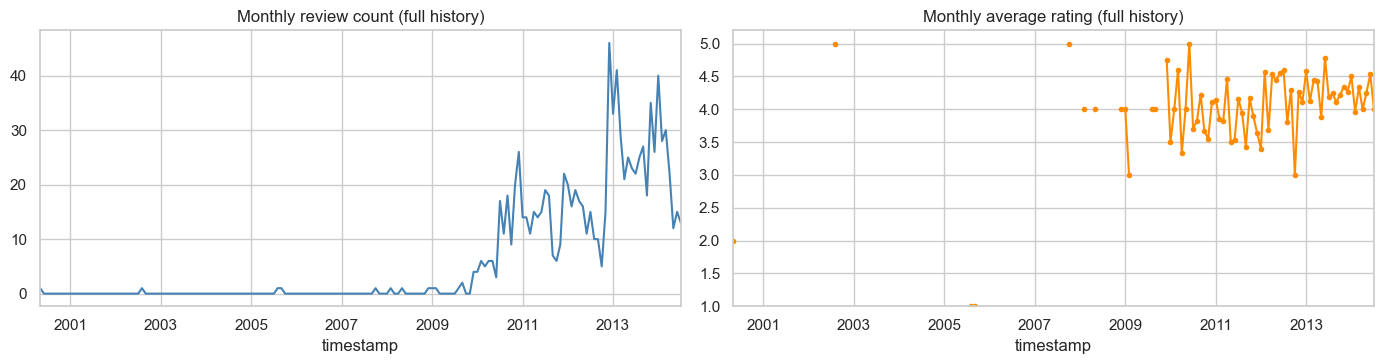

In [44]:
ts = df.set_index("timestamp").sort_index()

# full history (as requested in the starter notebook)
monthly_review_count = ts["rating"].resample("MS").count()
monthly_avg_rating = ts["rating"].resample("MS").mean()

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
monthly_review_count.plot(ax=ax[0], color="steelblue"); ax[0].set_title("Monthly review count (full history)")
monthly_avg_rating.plot(ax=ax[1], marker="o", linestyle="-", markersize=3, color="darkorange")
ax[1].set_title("Monthly average rating (full history)"); ax[1].set_ylim(1, 5.2)
plt.tight_layout(); plt.show()

### Monthly Review Count and Average Rating

- **Volume:** almost no reviews before 2009. Activity rises from 2010 and jumps sharply in early 2013, with a peak of about 46 reviews in a single month. Volume then stays around 15-35 per month.
- **Average rating:** early points (2000-2008) are isolated single reviews, so they swing between 1 and 5 and aren't reliable.
- **From 2010 on:** ratings are noisy month to month (about 3.0 to 5.0) but stay mostly between 3.5 and 4.5. There is a slight upward drift, with the 2013-2014 months clustering around 4.0-4.5.
-  customer satisfaction is fairly stable and positive. The 2013 spike in volume is not matched by a drop in ratings.

Months in window: 54 | months with 0 reviews: 0


,review_count,avg_rating,rolling_3m,log_count
timestamp,,,,
2010-01-01,4,3.500000,NaN,1.609438
2010-02-01,6,4.000000,NaN,1.945910
2010-03-01,5,4.600000,4.033333,1.791759
2010-04-01,6,3.333333,3.977778,1.945910
2010-05-01,6,4.000000,3.977778,1.945910


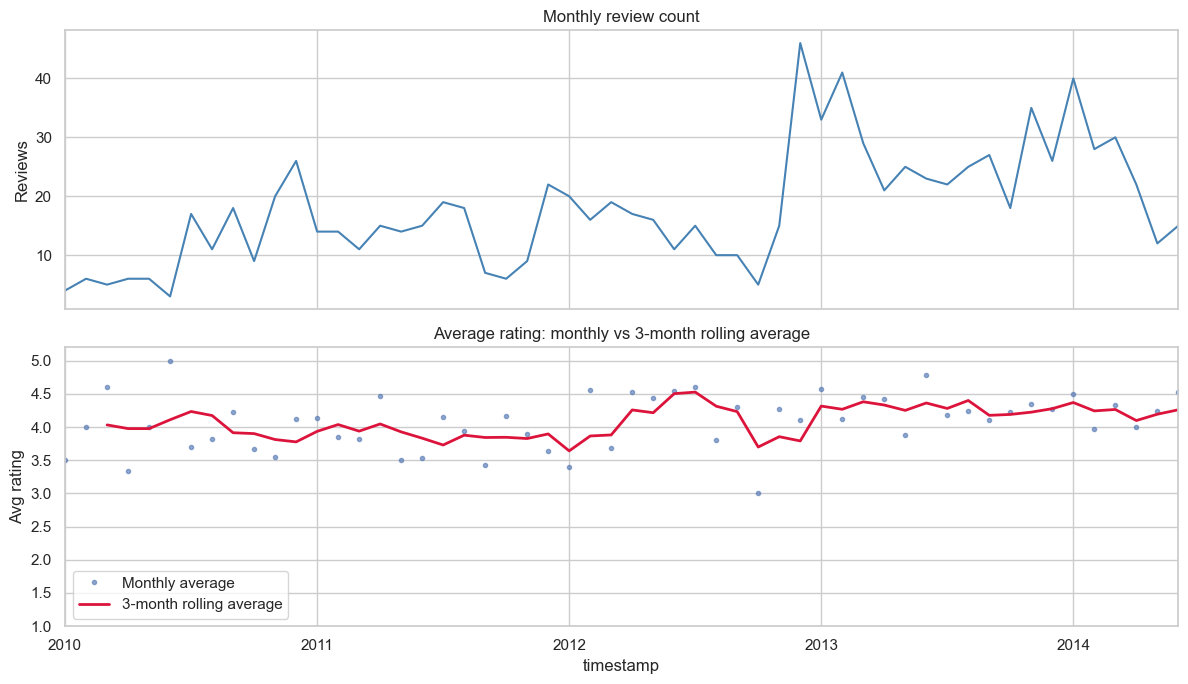

In [46]:
monthly = (ts["rating"].resample("MS").agg(["count", "mean"])
             .rename(columns={"count": "review_count", "mean": "avg_rating"})
             .loc["2010-01-01":"2014-06-01"].copy())

print("Months in window:", len(monthly), "| months with 0 reviews:", int((monthly["review_count"] == 0).sum()))
monthly["avg_rating"] = monthly["avg_rating"].interpolate()           # safety net (no gaps expected)
monthly["rolling_3m"] = monthly["avg_rating"].rolling(3).mean()       # 3-month rolling average
monthly["log_count"] = np.log1p(monthly["review_count"])              # variance-stabilising transform
display(monthly.head())

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
monthly["review_count"].plot(ax=ax[0], color="steelblue"); ax[0].set_title("Monthly review count"); ax[0].set_ylabel("Reviews")
monthly["avg_rating"].plot(ax=ax[1], marker="o", linestyle="", markersize=3, alpha=0.6, label="Monthly average")
monthly["rolling_3m"].plot(ax=ax[1], linewidth=2, color="crimson", label="3-month rolling average")
ax[1].set_title("Average rating: monthly vs 3-month rolling average"); ax[1].set_ylabel("Avg rating"); ax[1].set_ylim(1, 5.2); ax[1].legend()
plt.tight_layout(); plt.show()

## Trends: 
review volume grows strongly over the period. The average rating is noisy month to month but hovers in a narrow, high band; the rolling average removes much of the noise and shows whether satisfaction drifts up or down. Months with few reviews (early 2010) are especially noisy because a single review moves the average a lot.

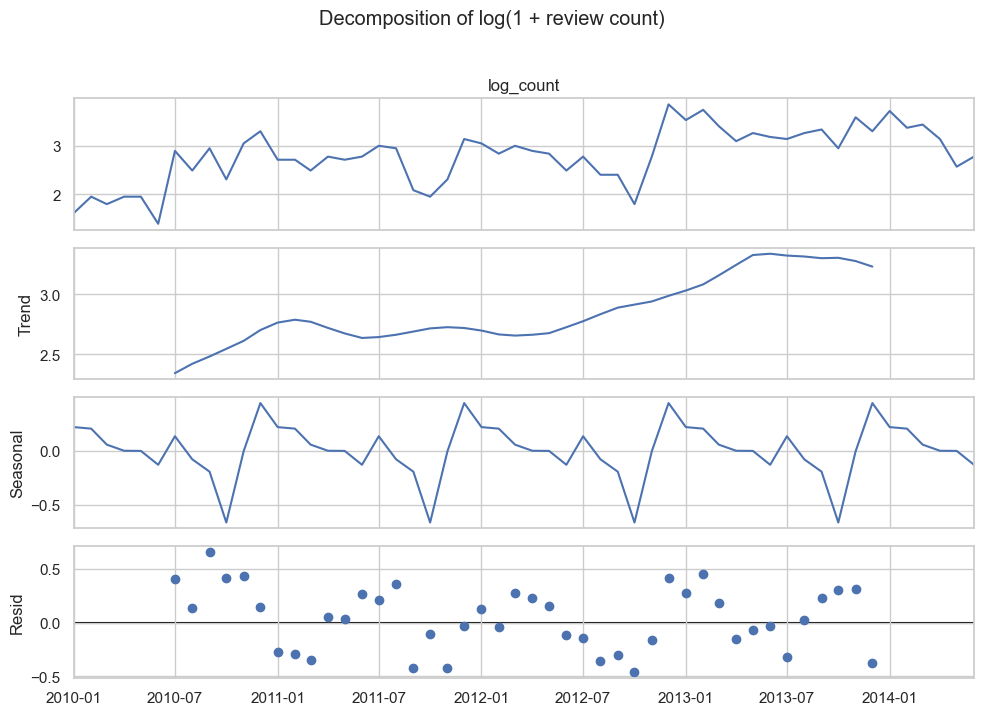

Seasonal strength for log(1 + review count): 0.47  (0 = none, 1 = purely seasonal)



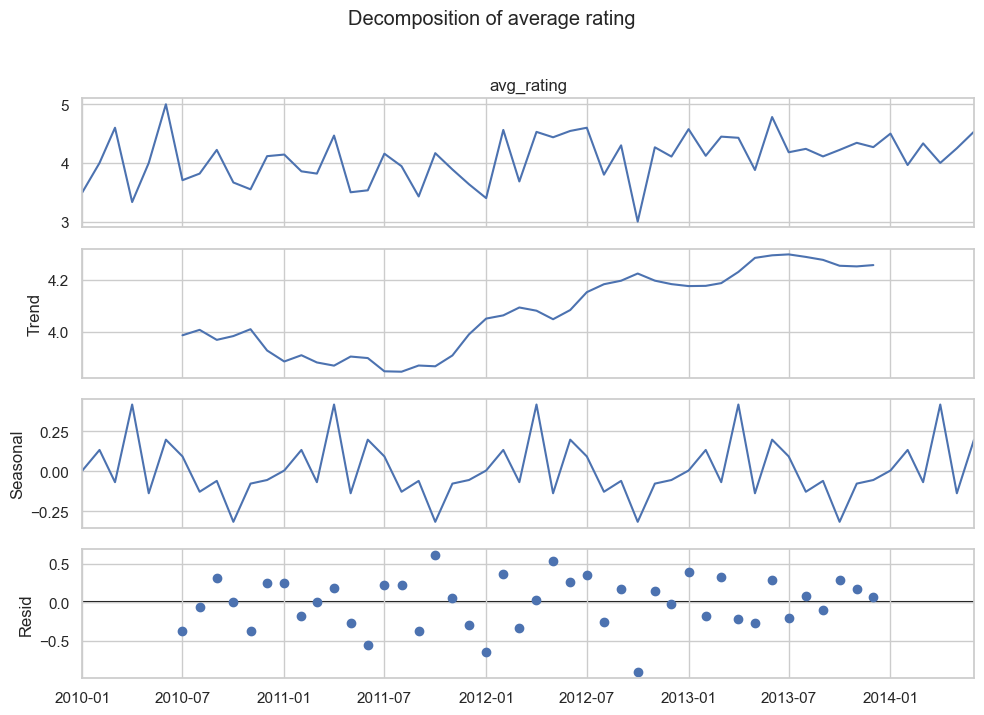

Seasonal strength for average rating: 0.23  (0 = none, 1 = purely seasonal)



In [47]:
# Decomposition: trend / seasonal / residual (additive; period = 12 months)
for col, title in [("log_count", "log(1 + review count)"), ("avg_rating", "average rating")]:
    dec = seasonal_decompose(monthly[col], model="additive", period=12)
    fig = dec.plot(); fig.set_size_inches(10, 7); fig.suptitle(f"Decomposition of {title}", y=1.02)
    plt.tight_layout(); plt.show()
    seas_strength = max(0, 1 - dec.resid.var() / (dec.resid + dec.seasonal).var())
    print(f"Seasonal strength for {title}: {seas_strength:.2f}  (0 = none, 1 = purely seasonal)\n")

## Decomposition Interpretation

## Review volume (log count)

Trend: rises from 2010, dips slightly in 2011-2012, then climbs in 2013 and levels off, so review activity grew over time.
Seasonality: a repeating yearly pattern with a strong low point around mid-year and a peak around the start of the year. Seasonal strength is 0.47, which is moderate.
Residuals: scattered around zero with no clear pattern, so trend and seasonality explain most of the structure.

## Average rating

Trend: dips slightly to about 3.9 in 2011, then rises to about 4.3 by 2013, so satisfaction improved.
Seasonality: weak (0.23), with small swings of about ±0.25 stars.
Residuals: large (up to ±0.8), so most month-to-month variation is noise.

 review volume has a clear trend and a moderate yearly pattern, so it needs transformation or differencing and is forecastable. The average rating is mostly noise around a stable level, so forecasts will have limited skill and a seasonal term is unlikely to help much.

## Stationarity tests and transformations

- **ADF:** H0 = the series has a unit root (non-stationary). *p < 0.05 → stationary.*
- **KPSS:** H0 = the series is stationary. *p > 0.05 → stationary.*

In [97]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import seasonal_decompose

warnings.filterwarnings("ignore")

In [98]:
def stationarity_report(series, name):
    s = series.dropna()
    adf = adfuller(s, autolag="AIC")
    kp = kpss(s, regression="c", nlags="auto")
    adf_ok, kpss_ok = adf[1] < 0.05, kp[1] > 0.05
    verdict = ("stationary" if adf_ok and kpss_ok else
               "non-stationary" if (not adf_ok and not kpss_ok) else "inconclusive (tests disagree)")
    return {"series": name, "n": len(s), "ADF stat": round(adf[0], 3), "ADF p": round(adf[1], 4),
            "KPSS stat": round(kp[0], 3), "KPSS p": round(kp[1], 4), "verdict": verdict}

tests = [
    stationarity_report(monthly["avg_rating"], "avg rating (raw)"),
    stationarity_report(monthly["avg_rating"].diff(), "avg rating, 1st difference"),
    stationarity_report(monthly["review_count"], "review count (raw)"),
    stationarity_report(monthly["log_count"], "log review count"),
    stationarity_report(monthly["log_count"].diff(), "log review count, 1st difference"),
    stationarity_report(monthly["log_count"].diff().diff(12), "log count, 1st + seasonal (12) difference"),
]
stationarity_table = pd.DataFrame(tests).set_index("series")
display(stationarity_table)

,n,ADF stat,ADF p,KPSS stat,KPSS p,verdict
series,,,,,,
avg rating (raw),54,-0.985,0.7587,0.668,0.0165,non-stationary
"avg rating, 1st difference",53,-7.052,0.0000,0.164,0.1000,stationary
review count (raw),54,-3.547,0.0069,0.715,0.0122,inconclusive (tests disagree)
log review count,54,-3.619,0.0054,0.730,0.0108,inconclusive (tests disagree)
"log review count, 1st difference",53,-4.438,0.0003,0.125,0.1000,stationary
"log count, 1st + seasonal (12) difference",41,-1.432,0.5667,0.064,0.1000,inconclusive (tests disagree)


## Stationarity Interpretation
Average rating (raw): non-stationary (ADF p = 0.76, KPSS p = 0.017), matching the upward drift in the decomposition.
After 1st difference: stationary on both tests, so d = 1.
Review count and log count: the tests disagree (ADF stationary, KPSS non-stationary), which suggests a trend.
Log count, 1st difference: stationary on both tests, so d = 1.
Seasonal difference (12): not needed, since it made ADF worse (p = 0.57).

Decision: use d = 1 for both series, plus a log transform for review count.

Differencing order chosen -> avg rating: d = 1 | log review count: d = 0


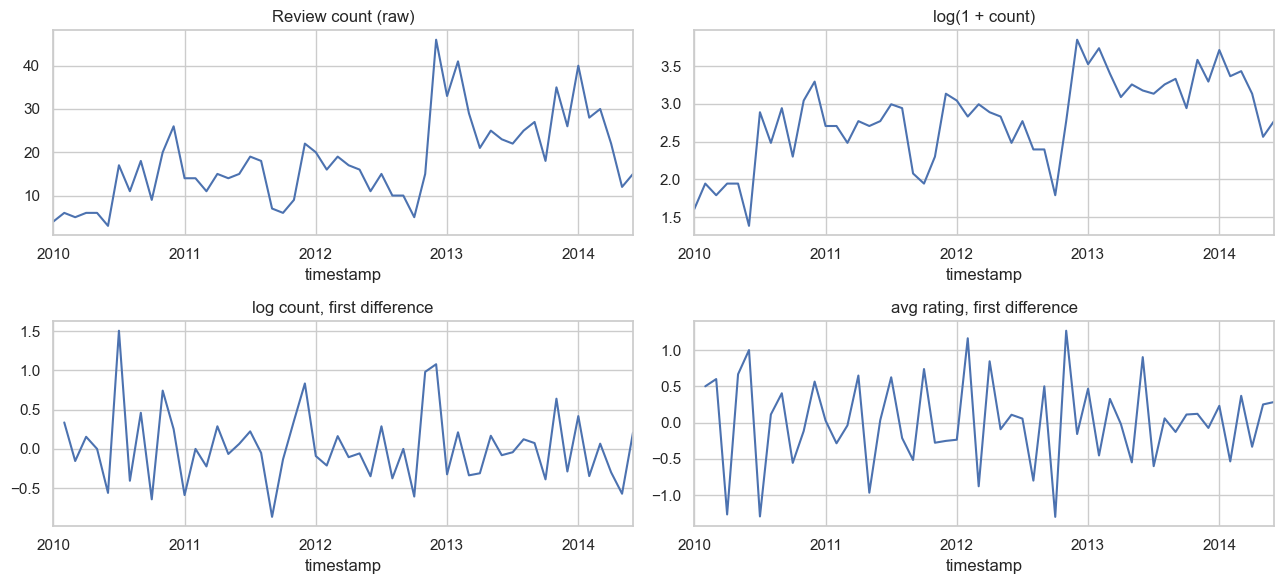

In [50]:
def choose_d(series, max_d=2, alpha=0.05):
    """Smallest number of differences for which the ADF test rejects a unit root."""
    s = series.copy()
    for d in range(max_d + 1):
        if adfuller(s.dropna(), autolag="AIC")[1] < alpha:
            return d
        s = s.diff()
    return max_d

d_rating = choose_d(monthly["avg_rating"])
d_count = choose_d(monthly["log_count"])
print(f"Differencing order chosen -> avg rating: d = {d_rating} | log review count: d = {d_count}")

fig, ax = plt.subplots(2, 2, figsize=(13, 6))
monthly["review_count"].plot(ax=ax[0, 0], title="Review count (raw)")
monthly["log_count"].plot(ax=ax[0, 1], title="log(1 + count)")
monthly["log_count"].diff().plot(ax=ax[1, 0], title="log count, first difference")
monthly["avg_rating"].diff().plot(ax=ax[1, 1], title="avg rating, first difference")
plt.tight_layout(); plt.show()

## Transformation Plots Interpretation
Review count (raw): clear upward trend, with a jump in 2013 and growing swings, so it is not stationary.
log(1 + count): the log transform narrows the swings, but the upward trend remains.
Log count, 1st difference: flat around zero with no trend and fairly constant spread, so the differencing removed the trend (one spike in mid-2010).
Avg rating, 1st difference: flat around zero, but jagged, because differencing a noisy series amplifies the noise.

##  ACF / PACF 
The PACF suggests the AR order (p) and the ACF the MA order (q) of the stationary series. We use them to *narrow* the search, then compare candidates objectively with **AIC/BIC**.

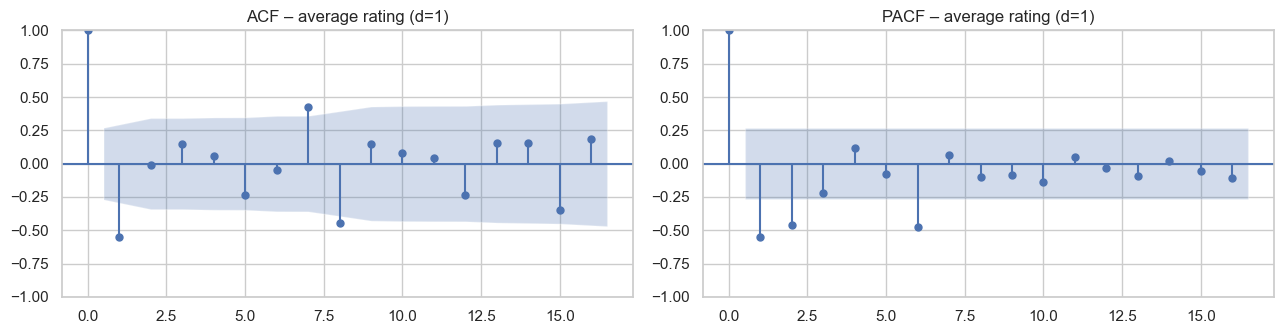

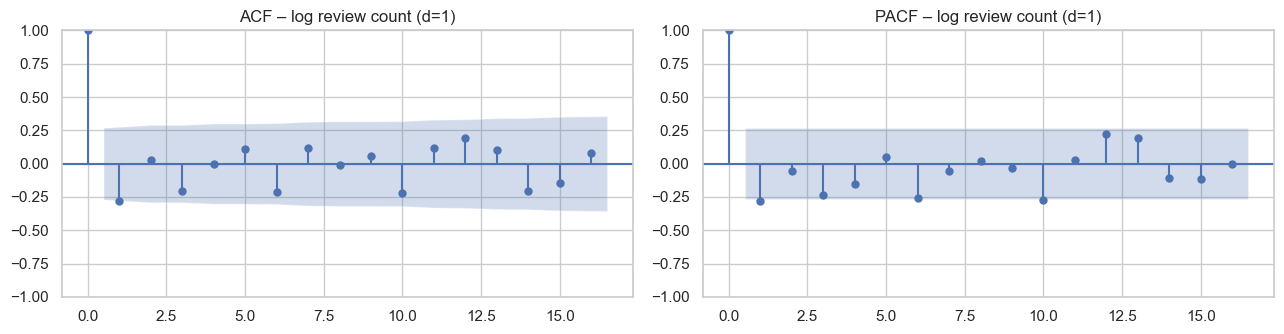

In [73]:
def plot_acf_pacf(series, d, title, lags=16):
    s = series.diff(d).dropna() if d > 0 else series
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
    plot_acf(s, lags=lags, ax=ax[0]); ax[0].set_title(f"ACF – {title} (d={d})")
    plot_pacf(s, lags=lags, ax=ax[1], method="ywm"); ax[1].set_title(f"PACF – {title} (d={d})")
    plt.tight_layout(); plt.show()

plot_acf_pacf(monthly["avg_rating"], d_rating, "average rating")
plot_acf_pacf(monthly["log_count"], d_count, "log review count")

## ACF / PACF 

What they show: how much a month’s value is related to previous months.

ACF: the overall link between a month and earlier months.
PACF: the direct link at each lag, with the in-between months removed.
Blue band: spikes outside it are real. Spikes inside it are noise.

## Average rating

There is one big negative spike at lag 1.
This means a high month is usually followed by a lower one, and the reverse. The ratings bounce around a steady level.
It suggests the model ARIMA(0,1,1).

Log review count (before differencing)

The bars shrink slowly (0.65, 0.48, 0.30...).
This means each month depends on the previous ones because of the upward trend.
It confirms the series still needs differencing (d = 1).

## Model selection and forecasting
Procedure for each series:

Hold out the last 6 months as a test set (no peeking).

Fit ARIMA(p,d,q) for p,q ∈ {0..3} on the training part and rank by AIC (and BIC, which penalises complexity more).

Also fit one seasonal candidate (adds a seasonal AR term at lag 12) to check whether seasonality helps.

Compare the best model's forecast against two baselines (naïve = last value, mean = training mean) using MAE and RMSE.

Check residuals (Ljung–Box), then refit on all data and forecast 6 months ahead with 95% intervals.

In [74]:
H = 6   # hold-out size and forecast horizon

def grid_search_arima(y, d, max_p=3, max_q=3):
    trend = "c" if d == 0 else "n"
    rows = []
    for p, q in itertools.product(range(max_p + 1), range(max_q + 1)):
        try:
            res = ARIMA(y, order=(p, d, q), trend=trend).fit()
            rows.append({"order": (p, d, q), "AIC": res.aic, "BIC": res.bic})
        except Exception:
            continue
    return pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)

def error_metrics(actual, pred):
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    return {"MAE": np.mean(np.abs(actual - pred)), "RMSE": np.sqrt(np.mean((actual - pred) ** 2))}

## settings and train/test split

In [75]:
# Average rating 
series, name, d = monthly["avg_rating"], "Average rating", 1
inv, clip, ylabel = (lambda x: x), (1, 5.2), "Avg rating (1-5)"

#  For review count, use these instead ---
# series, name, d = monthly["log_count"], "Monthly review count", 1
# inv, clip, ylabel = np.expm1, None, "Reviews per month"

trend = "c" if d == 0 else "n"
train, test = series.iloc[:-H], series.iloc[-H:]
print(len(train), "training months |", len(test), "test months")

48 training months | 6 test months


## order selection

In [76]:
import itertools, copy, html, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import seasonal_decompose

warnings.filterwarnings("ignore")

In [77]:


grid = grid_search_arima(train, d)
best_aic_order = grid.loc[grid["AIC"].idxmin(), "order"]
best_bic_order = grid.loc[grid["BIC"].idxmin(), "order"]
print(f"=== {name} ===")
display(grid.head(5).round(2))
print(f"Best by AIC: {best_aic_order} | best by BIC: {best_bic_order}")

=== Average rating ===


,order,AIC,BIC
0,"(2, 1, 3)",50.45,61.55
1,"(3, 1, 2)",53.39,64.49
2,"(3, 1, 3)",57.11,70.06
3,"(0, 1, 1)",59.21,62.91
4,"(0, 1, 2)",59.75,65.31


Best by AIC: (2, 1, 3) | best by BIC: (2, 1, 3)


## fit candidates and compare with baselines

In [78]:
candidates = {f"ARIMA{best_aic_order} [AIC-best]": dict(order=best_aic_order)}
if best_bic_order != best_aic_order:
    candidates[f"ARIMA{best_bic_order} [BIC-best]"] = dict(order=best_bic_order)
candidates[f"SARIMA{best_aic_order}x(1,0,0,12)"] = dict(order=best_aic_order, seasonal_order=(1, 0, 0, 12))

rows, fcs = [], {}
for label, kw in candidates.items():
    try:
        res = ARIMA(train, trend=trend, **kw).fit()
        fc = res.get_forecast(H)
        fcs[label] = (fc.predicted_mean.values, fc.conf_int(alpha=0.05).values)
        rows.append({"model": label, "AIC": res.aic, "BIC": res.bic,
                     **error_metrics(inv(test.values), inv(fcs[label][0]))})
    except Exception as e:
        print(f"could not fit {label}: {e}")

naive = np.repeat(train.iloc[-1], H)
mean_ = np.repeat(train.mean(), H)
for label, fc in [("Baseline: naive (last value)", naive), ("Baseline: training mean", mean_)]:
    rows.append({"model": label, "AIC": np.nan, "BIC": np.nan,
                 **error_metrics(inv(test.values), inv(fc))})

comparison = pd.DataFrame(rows).set_index("model")
display(comparison.round(3))
best_label = [l for l in comparison.index if not l.startswith("Baseline")][0]

,AIC,BIC,MAE,RMSE
model,,,,
"ARIMA(2, 1, 3) [AIC-best]",50.449,61.550,0.210,0.231
"SARIMA(2, 1, 3)x(1,0,0,12)",52.384,65.335,0.221,0.242
Baseline: naive (last value),NaN,NaN,0.192,0.221
Baseline: training mean,NaN,NaN,0.255,0.300


## hold-out forecast plot

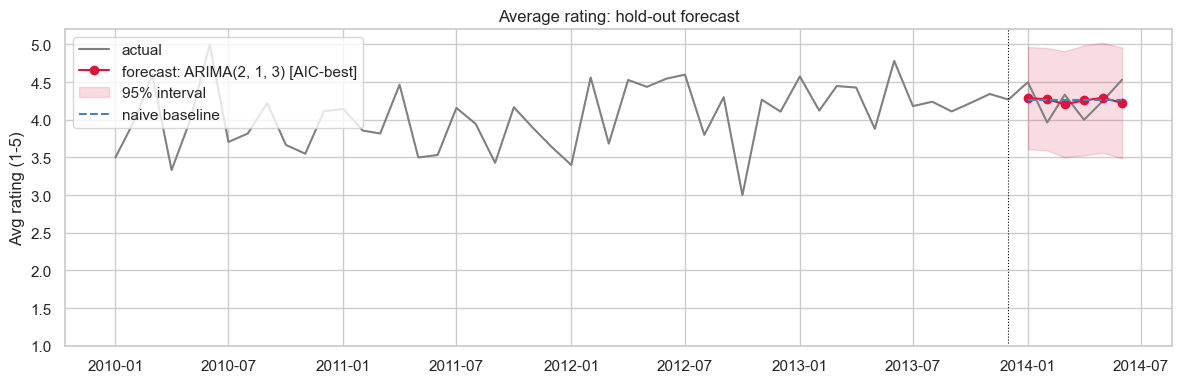

In [79]:
fc_mean, fc_ci = fcs[best_label]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(series.index, inv(series.values), color="gray", label="actual")
ax.plot(test.index, inv(fc_mean), color="crimson", marker="o", label=f"forecast: {best_label}")
ax.fill_between(test.index, inv(fc_ci[:, 0]), inv(fc_ci[:, 1]), color="crimson", alpha=0.15, label="95% interval")
ax.plot(test.index, inv(naive), color="steelblue", ls="--", label="naive baseline")
ax.axvline(train.index[-1], color="black", lw=0.8, ls=":")
ax.set_title(f"{name}: hold-out forecast"); ax.set_ylabel(ylabel); ax.legend(loc="upper left")
if clip: ax.set_ylim(*clip)
plt.tight_layout(); plt.show()

# residual check

Ljung-Box p = 0.552 -> residuals look like white noise


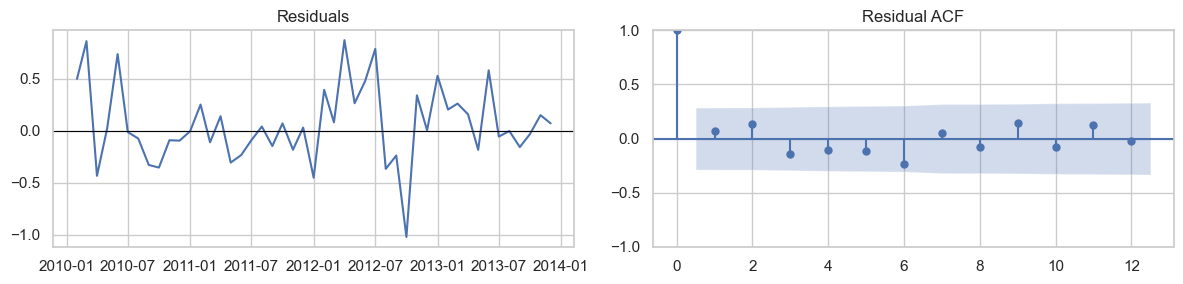

In [80]:
res_best = ARIMA(train, order=best_aic_order, trend=trend).fit()
resid = res_best.resid.iloc[max(d, 1):]
lb_p = float(acorr_ljungbox(resid, lags=[10], return_df=True)["lb_pvalue"].iloc[0])
print(f"Ljung-Box p = {lb_p:.3f} ->", "residuals look like white noise" if lb_p > 0.05
      else "some autocorrelation left in residuals")

fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].plot(resid.index, resid.values); ax[0].axhline(0, color="black", lw=0.8); ax[0].set_title("Residuals")
plot_acf(resid, lags=12, ax=ax[1]); ax[1].set_title("Residual ACF")
plt.tight_layout(); plt.show()

## refit on all data and forecast the next 6 months

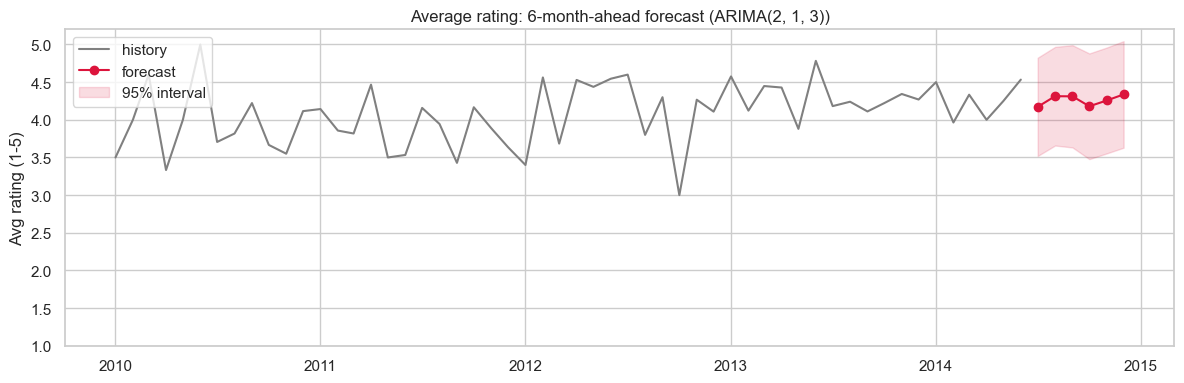

,forecast,lower,upper
2014-07-01,4.17,3.52,4.82
2014-08-01,4.31,3.66,4.97
2014-09-01,4.31,3.63,4.99
2014-10-01,4.18,3.48,4.88
2014-11-01,4.26,3.55,4.96
2014-12-01,4.34,3.63,5.04


In [81]:
final = ARIMA(series, order=best_aic_order, trend=trend).fit()
ff = final.get_forecast(H)
f_mean, f_ci = ff.predicted_mean, ff.conf_int(alpha=0.05)
f_lo, f_hi = inv(f_ci.iloc[:, 0].values), inv(f_ci.iloc[:, 1].values)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(series.index, inv(series.values), color="gray", label="history")
ax.plot(f_mean.index, inv(f_mean.values), color="crimson", marker="o", label="forecast")
ax.fill_between(f_mean.index, f_lo, f_hi, color="crimson", alpha=0.15, label="95% interval")
ax.set_title(f"{name}: {H}-month-ahead forecast (ARIMA{best_aic_order})"); ax.set_ylabel(ylabel); ax.legend(loc="upper left")
if clip: ax.set_ylim(*clip)
plt.tight_layout(); plt.show()

display(pd.DataFrame({"forecast": inv(f_mean.values), "lower": f_lo, "upper": f_hi}, index=f_mean.index).round(2))

## Average Rating: Forecast Output Interpretation
Model choice: ARIMA(2,1,3) has the lowest AIC and BIC, so both criteria agree.
Hold-out plot: the forecast stays flat at about 4.2-4.3 while the actual ratings bounce around it. The model captures the level but not the month-to-month swings.
Residuals: Ljung-Box p = 0.552 (above 0.05), and the residual ACF bars stay inside the blue band. The residuals look like white noise, so the model has used the available patterns.
6-month forecast: ratings stay steady at about 4.2-4.3 through December 2014, with wide 95% intervals (about ±0.7 stars).

Takeaway: the model is statistically sound, but the rating is mostly random noise around 4.2 stars, so forecasts are flat and uncertain. Use the 3-month rolling average to monitor satisfaction.

## Forecast 2 monthly review volume 

In [85]:
import itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
warnings.filterwarnings("ignore")

H = 6                                   # hold-out size and forecast horizon
series = monthly["log_count"]           # log(1 + review count)
name, d = "Monthly review count", 1     # d = 1: one difference
inv = np.expm1                          # convert log scale back to review counts
trend = "c" if d == 0 else "n"
train, test = series.iloc[:-H], series.iloc[-H:]

def error_metrics(actual, pred):
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    return {"MAE": np.mean(np.abs(actual - pred)), "RMSE": np.sqrt(np.mean((actual - pred) ** 2))}

print(len(train), "training months |", len(test), "test months")

48 training months | 6 test months


## order selection

In [86]:
rows = []
for p, q in itertools.product(range(4), range(4)):
    try:
        r = ARIMA(train, order=(p, d, q), trend=trend).fit()
        rows.append({"order": (p, d, q), "AIC": r.aic, "BIC": r.bic})
    except Exception:
        continue
grid = pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)
best_aic_order = grid.loc[grid["AIC"].idxmin(), "order"]
best_bic_order = grid.loc[grid["BIC"].idxmin(), "order"]

print(f"=== {name} ===")
display(grid.head(5).round(2))
print(f"Best by AIC: {best_aic_order} | best by BIC: {best_bic_order}")

=== Monthly review count ===


,order,AIC,BIC
0,"(2, 1, 3)",59.40,70.50
1,"(1, 1, 1)",60.31,65.87
2,"(0, 1, 3)",60.75,68.15
3,"(0, 1, 1)",60.76,64.46
4,"(3, 1, 3)",61.36,74.32


Best by AIC: (2, 1, 3) | best by BIC: (0, 1, 1)


## hold-out comparison with baselines

In [87]:
candidates = {f"ARIMA{best_aic_order} [AIC-best]": dict(order=best_aic_order)}
if best_bic_order != best_aic_order:
    candidates[f"ARIMA{best_bic_order} [BIC-best]"] = dict(order=best_bic_order)
candidates[f"SARIMA{best_aic_order}x(1,0,0,12)"] = dict(order=best_aic_order, seasonal_order=(1, 0, 0, 12))

results_rows, fcs = [], {}
for label, kw in candidates.items():
    try:
        res = ARIMA(train, trend=trend, **kw).fit()
        fc = res.get_forecast(H)
        fcs[label] = (fc.predicted_mean.values, fc.conf_int(alpha=0.05).values)
        results_rows.append({"model": label, "AIC": res.aic, "BIC": res.bic,
                             **error_metrics(inv(test.values), inv(fcs[label][0]))})
    except Exception as e:
        print(f"could not fit {label}: {e}")

naive = np.repeat(train.iloc[-1], H)
mean_ = np.repeat(train.mean(), H)
for label, fc in [("Baseline: naive (last value)", naive), ("Baseline: training mean", mean_)]:
    results_rows.append({"model": label, "AIC": np.nan, "BIC": np.nan,
                         **error_metrics(inv(test.values), inv(fc))})

comparison = pd.DataFrame(results_rows).set_index("model")
print("Hold-out comparison (errors in review counts; lower is better):")
display(comparison.round(3))
best_label = [l for l in comparison.index if not l.startswith("Baseline")][0]

Hold-out comparison (errors in review counts; lower is better):


,AIC,BIC,MAE,RMSE
model,,,,
"ARIMA(2, 1, 3) [AIC-best]",59.397,70.498,8.729,9.515
"ARIMA(0, 1, 1) [BIC-best]",60.758,64.458,8.167,9.758
"SARIMA(2, 1, 3)x(1,0,0,12)",56.322,69.273,9.378,10.647
Baseline: naive (last value),NaN,NaN,8.167,9.566
Baseline: training mean,NaN,NaN,10.749,13.665


## hold-out forecast plot

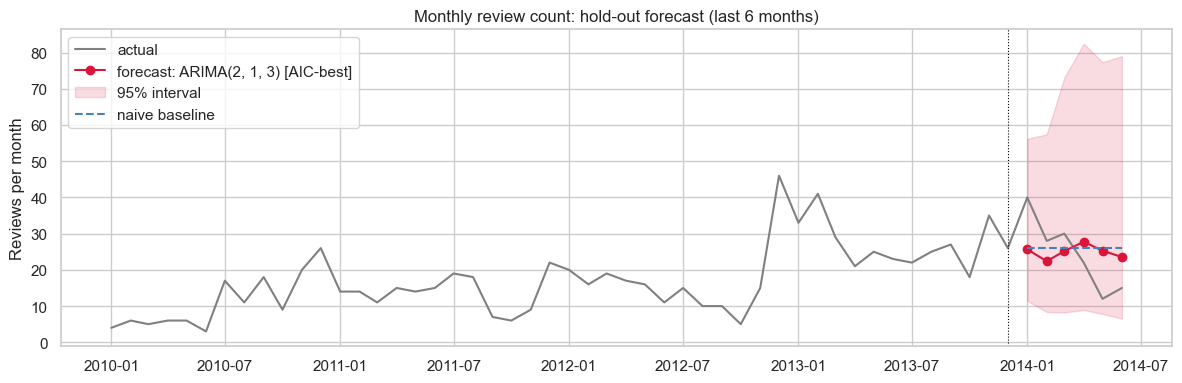

In [88]:
fc_mean, fc_ci = fcs[best_label]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(series.index, inv(series.values), color="gray", label="actual")
ax.plot(test.index, inv(fc_mean), color="crimson", marker="o", label=f"forecast: {best_label}")
ax.fill_between(test.index, inv(fc_ci[:, 0]), inv(fc_ci[:, 1]), color="crimson", alpha=0.15, label="95% interval")
ax.plot(test.index, inv(naive), color="steelblue", ls="--", label="naive baseline")
ax.axvline(train.index[-1], color="black", lw=0.8, ls=":")
ax.set_title(f"{name}: hold-out forecast (last {H} months)"); ax.set_ylabel("Reviews per month")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

## residual check

Ljung-Box p = 0.930 -> residuals look like white noise


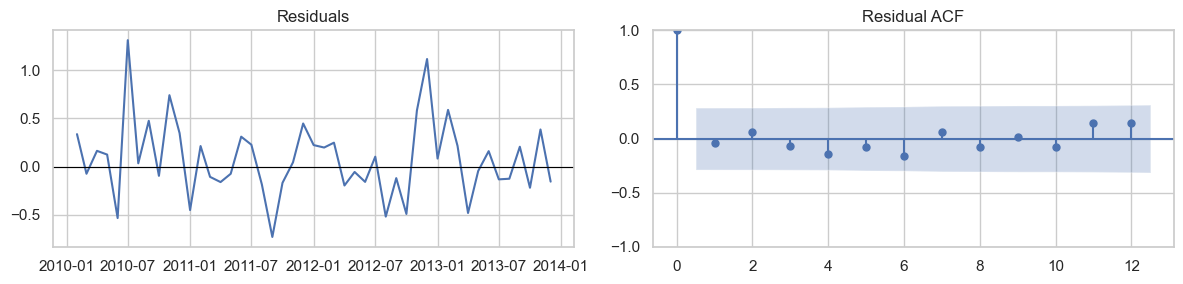

In [90]:
res_best = ARIMA(train, order=best_aic_order, trend=trend).fit()
resid = res_best.resid.iloc[max(d, 1):]
lb_p = float(acorr_ljungbox(resid, lags=[10], return_df=True)["lb_pvalue"].iloc[0])
print(f"Ljung-Box p = {lb_p:.3f} ->", "residuals look like white noise" if lb_p > 0.05
      else "some autocorrelation left in residuals")

fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].plot(resid.index, resid.values); ax[0].axhline(0, color="black", lw=0.8); ax[0].set_title("Residuals")
plot_acf(resid, lags=12, ax=ax[1]); ax[1].set_title("Residual ACF")
plt.tight_layout(); plt.show()

## refit on all data and forecast the next 6 months

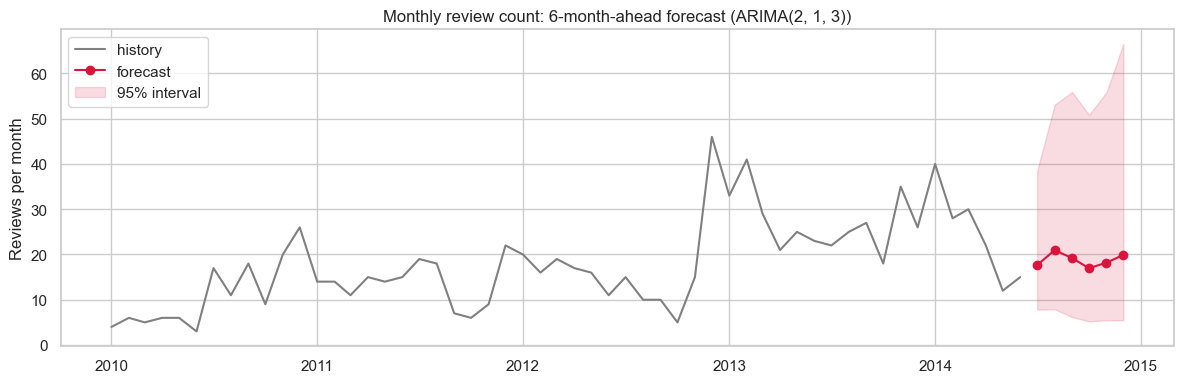

Next 6 months (reviews per month):


,forecast,lower,upper
2014-07-01,18.0,8.0,38.0
2014-08-01,21.0,8.0,53.0
2014-09-01,19.0,6.0,56.0
2014-10-01,17.0,5.0,51.0
2014-11-01,18.0,5.0,56.0
2014-12-01,20.0,5.0,67.0


In [91]:
final = ARIMA(series, order=best_aic_order, trend=trend).fit()
ff = final.get_forecast(H)
f_mean, f_ci = ff.predicted_mean, ff.conf_int(alpha=0.05)
f_lo, f_hi = inv(f_ci.iloc[:, 0].values), inv(f_ci.iloc[:, 1].values)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(series.index, inv(series.values), color="gray", label="history")
ax.plot(f_mean.index, inv(f_mean.values), color="crimson", marker="o", label="forecast")
ax.fill_between(f_mean.index, f_lo, f_hi, color="crimson", alpha=0.15, label="95% interval")
ax.set_title(f"{name}: {H}-month-ahead forecast (ARIMA{best_aic_order})"); ax.set_ylabel("Reviews per month")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

print("Next 6 months (reviews per month):")
display(pd.DataFrame({"forecast": inv(f_mean.values), "lower": f_lo, "upper": f_hi},
                     index=f_mean.index).round(0))

## Forecast Interpretation
Hold-out plot: the forecast is flat at about 22-28 reviews per month, while the actual volume fell from about 30 to 12-15. The model missed this drop, and the wide interval (about 8 to 80) shows how uncertain it was.
Residuals: the Ljung-Box p-value is well above 0.05 and the residual ACF bars stay inside the blue band, so the residuals look like white noise and the model has used the available patterns.
6-month forecast: volume stays steady at about 17-21 reviews per month through December 2014.
Uncertainty: the 95% interval is wide and gets wider over time (for example 5 to 67 in December). Only the rough level can be trusted, not any single month.

Takeaway: plan support staffing for roughly 20 reviews a month, but prepare for anywhere from about 5 to 60, since volume has jumped around (the 2013 spike). Re-fit the model monthly as new data arrives.

In [94]:
beat_baselines(comparison, "Monthly review count")

--- Monthly review count ---
ARIMA(2, 1, 3) [AIC-best]: RMSE = 9.515 | naive = 9.566 | mean = 13.665
vs naive: +0.5% | vs mean: +30.4%  (positive = ARIMA is better)
Lowest RMSE on hold-out: ARIMA(2, 1, 3) [AIC-best]



In [95]:
beat_baselines(comparison, "Monthly review count")

--- Monthly review count ---
ARIMA(2, 1, 3) [AIC-best]: RMSE = 9.515 | naive = 9.566 | mean = 13.665
vs naive: +0.5% | vs mean: +30.4%  (positive = ARIMA is better)
Lowest RMSE on hold-out: ARIMA(2, 1, 3) [AIC-best]



In [96]:
rating_comparison = pd.DataFrame(
    {"RMSE": [0.231, 0.242, 0.221, 0.300]},
    index=["ARIMA(2, 1, 3) [AIC-best]", "SARIMA(2, 1, 3)x(1,0,0,12)",
           "Baseline: naive (last value)", "Baseline: training mean"])

beat_baselines(rating_comparison, "Average rating")

--- Average rating ---
ARIMA(2, 1, 3) [AIC-best]: RMSE = 0.231 | naive = 0.221 | mean = 0.300
vs naive: -4.5% | vs mean: +23.0%  (positive = ARIMA is better)
Lowest RMSE on hold-out: Baseline: naive (last value)



### ARIMA vs Baselines: Summary

| Series | ARIMA RMSE | Naive RMSE | Mean RMSE | Winner |
|---|---|---|---|---|
| Review count | 9.52 | 9.57 | 13.67 | ARIMA (barely) |
| Average rating | 0.231 | 0.221 | 0.300 | Naive |

- **Review count:** ARIMA is 30% better than the training mean but only 0.5% better than the naive baseline, which is essentially a tie.
- **Average rating:** the naive baseline is 4.5% better than ARIMA, which is still 23% better than the mean.
- **Why:** the series are noisy and have only about 50 months of data, so ARIMA struggles to beat "repeat last month".

**Takeaway:** ARIMA clearly beats a long-term average but adds little over a simple last-value guess. 

### Part 2 Reflection

**Review activity:** review volume grew strongly over time. Before 2010 there were only a few isolated reviews, volume rose through 2010-2012, jumped in early 2013 to a peak of about 46 reviews in a month, and then settled at roughly 15-30 per month. The decomposition shows a rising trend and a moderate yearly pattern (seasonal strength 0.47).

**Customer ratings:** ratings are high and fairly stable, mostly between 3.5 and 4.5 stars. The trend dips slightly to about 3.9 in 2011 and then rises to about 4.3 by 2013. The 3-month rolling average shows this more clearly than the noisy monthly values, and the seasonal pattern is weak (0.23).

**Link between the two:** the jump in review volume in 2013 did not cause a drop in ratings, so satisfaction held up as the customer base grew.

**Forecasting:** the review count needed a log transform and one difference to become stationary, and ARIMA(2,1,3) only just beat the naive baseline (RMSE 9.52 vs 9.57). The average rating is mostly noise around a stable level, so the naive baseline was slightly better than ARIMA (0.221 vs 0.231). The forecasts predict steady volume of about 17-21 reviews per month and ratings of about 4.2-4.3, with wide intervals.

**Implication:** use the 3-month rolling average to monitor satisfaction, and plan support staffing around the volume forecast and its interval rather than single-month predictions.

## Part 3: Neural Networks

In this section, you will transform text reviews into numerical features, train a neural network to predict ratings, and evaluate model performance.


In [135]:
# ===================================
# Part 3: Neural Networks Starter Code
# ===================================

# TODO: Import the libraries you need for:
# - data handling
# - train/test splitting
# - text vectorization
# - model building
# - model evaluation

# You will likely need tools from:
# - pandas / numpy
# - sklearn
# - tensorflow / keras

# TODO: Load the dataset.
# df = ...

# TODO: Define:
# X as the review text column
# y as the rating column
# If needed, adjust y so the classes are numbered appropriately for your model.

# TODO: Vectorize the text using TF-IDF.
# Suggested question:
# - How many features do you want to keep?

# vectorizer = ...
# X_tfidf = ...

# TODO: Split the data into training and testing sets.
# Use stratify=y to preserve class balance.

# TODO: One-hot encode the target values if your neural network setup requires it.

# TODO: Build a neural network model.
# Include:
# - an input layer
# - at least one hidden layer
# - an output layer suitable for multi-class classification

# model = ...

# TODO: Compile the model.
# Think about:
# - optimizer
# - loss function
# - evaluation metric(s)

# TODO: Train the model and store the training history.
# history = ...

# TODO: Evaluate the model on the test set.

# TODO: Generate predictions on the test set.

# TODO: Create a classification report and/or confusion matrix to assess performance.

# Reflection prompt:
# Which rating classes does the model predict well, and which ones are harder to classify?


In [100]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix,
                             mean_absolute_error, mean_squared_error, r2_score)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers


In [101]:
df = pd.read_csv("amazon_reviews_lab.csv")

In [102]:
df.head()

,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


In [103]:
df.shape

(997, 9)

In [129]:
df["clean_text"] = df["review_text"].apply(lambda t: " ".join(preprocess_text(t)))
X_text = df["clean_text"]             # text input for the train/test split
y = df["rating"] - 1                  # classes 0..4 (Keras expects labels starting at 0)
CLASS_NAMES = [f"{r} star" for r in range(1, 6)]

In [130]:
SEED = 42   # fixed random seed so the split is reproducible

# 80% train+val / 20% test, then 15% of the training part as a validation set (all stratified)
X_train_txt, X_test_txt, y_train, y_test = train_test_split(X_text, y, test_size=0.20, stratify=y, random_state=SEED)
X_tr_txt, X_val_txt, y_tr, y_val = train_test_split(X_train_txt, y_train, test_size=0.15, stratify=y_train, random_state=SEED)
print("train / val / test sizes:", len(X_tr_txt), len(X_val_txt), len(X_test_txt))

train / val / test sizes: 677 120 200


In [109]:
# TF-IDF fitted on the TRAINING split only (no information leaks from val/test)
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_tr = vectorizer.fit_transform(X_tr_txt).toarray().astype("float32")
X_val = vectorizer.transform(X_val_txt).toarray().astype("float32")
X_test = vectorizer.transform(X_test_txt).toarray().astype("float32")
print("Feature matrix shape (train):", X_tr.shape)

y_tr, y_val, y_test = y_tr.values, y_val.values, y_test.values
y_tr_oh = keras.utils.to_categorical(y_tr, 5)
y_val_oh = keras.utils.to_categorical(y_val, 5)

Feature matrix shape (train): (677, 5000)


In [110]:
# imbalance handling: weight each class inversely to its frequency
cw = compute_class_weight("balanced", classes=np.arange(5), y=y_tr)
class_weights = dict(enumerate(cw))
print("Class weights:", {CLASS_NAMES[k]: round(v, 2) for k, v in class_weights.items()})

Class weights: {'1 star': np.float64(2.26), '2 star': np.float64(4.23), '3 star': np.float64(2.12), '4 star': np.float64(1.07), '5 star': np.float64(0.34)}


## Design decisions

TF-IDF down-weights words that appear in every review and up-weights distinctive ones; unigrams + bigrams (battery life, not good) recover a little word order; 5,000 features keep the input small relative to ~700 training examples. sublinear_tf dampens the effect of very long reviews.
The vectorizer is fitted on the training split only fitting on all data before splitting would leak test vocabulary/IDF statistics.
A separate validation set is used for early stopping and model selection, so the test set is only used for the final report.
Class weights counter the dominance of 5-star reviews.

## Reference baselines

In [111]:
def evaluate(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "macro_F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
            "within_1_star": float(np.mean(np.abs(y_true - y_pred) <= 1))}

results = []   # collects every model for the final comparison

dummy = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
logreg = LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_tr, y_tr)

for name, mdl in [("Baseline: always predict 5 star", dummy), ("Baseline: logistic regression (balanced)", logreg)]:
    results.append({"model": name, **{f"val_{k}": v for k, v in evaluate(y_val, mdl.predict(X_val)).items()},
                    **{f"test_{k}": v for k, v in evaluate(y_test, mdl.predict(X_test)).items()}})
display(pd.DataFrame(results).set_index("model").round(3))

,val_accuracy,val_macro_F1,val_within_1_star,test_accuracy,test_macro_F1,test_within_1_star
model,,,,,,
Baseline: always predict 5 star,0.583,0.147,0.775,0.58,0.147,0.77
Baseline: logistic regression (balanced),0.567,0.348,0.767,0.58,0.384,0.82


## Interpretation
The "always 5 star" baseline shows how high accuracy gets without learning anything (the majority-class share) while its macro-F1 is very low. That is why macro-F1 (average F1 over the five classes, treating each equally) is our main selection metric, with accuracy and "within ±1 star" as supporting metrics.

### The MLP

Architecture: Input(5000) → Dense(256, ReLU) → Dropout(0.5) → Dense(64, ReLU) → Dropout(0.3) → Dense(5, softmax)

Choice	:Reason

ReLU hidden layers	:avoids vanishing gradients, cheap, standard for MLPs

Softmax output with 5 units	:produces a probability for each rating class

Categorical cross-entropy	:the correct loss for multi-class probabilities (labels are one-hot)

Dropout + L2	:with 700 examples and 5,000 inputs the network can memorise the training set easily

Adam (lr = 1e-3):	adaptive learning rate; robust default

Early stopping on validation loss	:stops when generalisation stops improving and restores the best weights


## Build

In [112]:

def build_mlp(input_dim, hidden=(256, 64), dropout=0.5, l2=1e-4, optimizer="adam", lr=1e-3, n_classes=5):
    model = keras.Sequential([layers.Input(shape=(input_dim,))])
    for i, units in enumerate(hidden):
        model.add(layers.Dense(units, activation="relu", kernel_regularizer=regularizers.l2(l2)))
        if dropout > 0:
            model.add(layers.Dropout(dropout if i == 0 else dropout * 0.6))
    model.add(layers.Dense(n_classes, activation="softmax"))
    optimizers = {"adam": keras.optimizers.Adam(lr), "rmsprop": keras.optimizers.RMSprop(lr),
                  "sgd": keras.optimizers.SGD(lr, momentum=0.9)}
    model.compile(optimizer=optimizers[optimizer], loss="categorical_crossentropy", metrics=["accuracy"])
    return model

## Train

In [113]:
def train_model(model, use_class_weights=True, epochs=80, batch_size=32):
    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)
    return model.fit(X_tr, y_tr_oh, validation_data=(X_val, y_val_oh), epochs=epochs, batch_size=batch_size,
                     class_weight=class_weights if use_class_weights else None, callbacks=[early_stop], verbose=0)

In [114]:
def predict_classes(model, X):
    return np.argmax(model.predict(X, verbose=0), axis=1)

tf.keras.utils.set_random_seed(SEED)
model = build_mlp(X_tr.shape[1])
model.summary()
history = train_model(model)
print("Epochs run (early stopping):", len(history.history["loss"]))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │       1,280,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │          16,448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 5)                   │             325 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,297,029 (4.95 MB)

 Trainable params: 1,297,029 (4.95 MB)

 Non-trainable params: 0 (0.00 B)

Epochs run (early stopping): 13


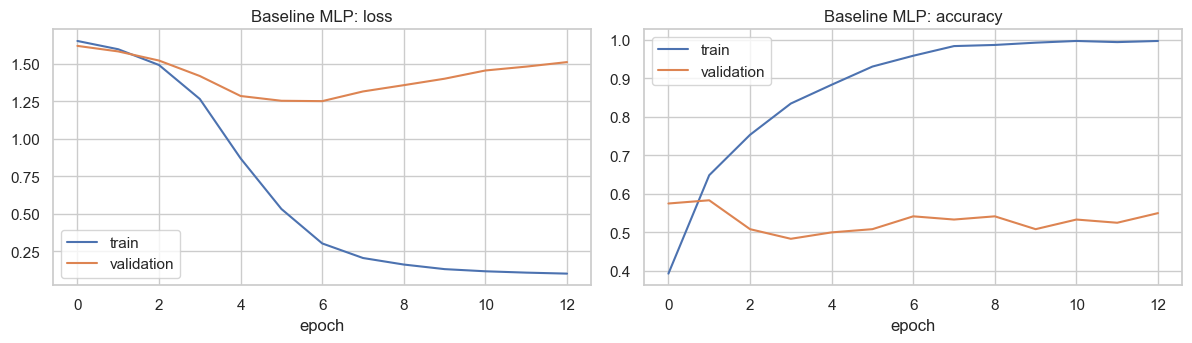

In [115]:
def plot_history(h, title="Training history"):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
    ax[0].plot(h.history["loss"], label="train"); ax[0].plot(h.history["val_loss"], label="validation")
    ax[0].set_title(f"{title}: loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h.history["accuracy"], label="train"); ax[1].plot(h.history["val_accuracy"], label="validation")
    ax[1].set_title(f"{title}: accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

plot_history(history, "Baseline MLP")

### Baseline MLP: Training Curves Interpretation

- **Training:** loss falls steadily and accuracy climbs to almost 100%, so the model learns the training reviews almost perfectly.
- **Validation:** loss reaches its lowest point at about epoch 5-6 (around 1.25) and then rises, while accuracy stays flat at about 50-55%.
- **Gap:** training accuracy near 100% against validation accuracy near 55% is clear **overfitting**. The model memorises the training reviews instead of learning patterns that generalise.
- **Early stopping:** it stopped training at epoch 12 and restored the best weights from about epoch 6, which is the right behaviour.

**Takeaway:** with only about 680 training reviews and 5,000 features, the network overfits quickly. Dropout, L2 regularisation, early stopping and smaller networks are needed,

## Systematic experiments

,epochs,train_acc,val_acc,val_macro_F1,test_acc,test_macro_F1,test_within_1,overfit_gap (train-val acc)
model,,,,,,,,
"D 256-64, dropout, RMSprop",15,0.973,0.567,0.353,0.510,0.302,0.800,0.407
"E 256-64, dropout, SGD+momentum",47,0.954,0.567,0.313,0.555,0.299,0.805,0.388
"F 512-128-32, dropout, Adam",12,0.990,0.508,0.281,0.485,0.275,0.805,0.481
"B 256-64, dropout, Adam",13,0.994,0.542,0.254,0.540,0.294,0.815,0.452
"A 1x64, no dropout, Adam",20,0.996,0.542,0.253,0.555,0.311,0.815,0.454
"C 256-64, dropout, Adam, NO class wts",10,0.665,0.583,0.149,0.580,0.148,0.775,0.081


Best configuration by validation macro-F1: D  256-64, dropout, RMSprop


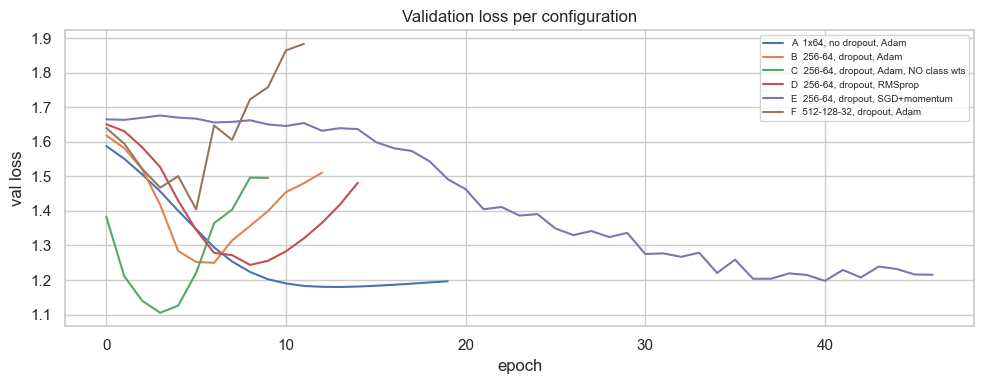

In [116]:
configs = [
    dict(name="A  1x64, no dropout, Adam",              hidden=(64,),         dropout=0.0, optimizer="adam",    lr=1e-3, cw=True),
    dict(name="B  256-64, dropout, Adam",               hidden=(256, 64),     dropout=0.5, optimizer="adam",    lr=1e-3, cw=True),
    dict(name="C  256-64, dropout, Adam, NO class wts", hidden=(256, 64),     dropout=0.5, optimizer="adam",    lr=1e-3, cw=False),
    dict(name="D  256-64, dropout, RMSprop",            hidden=(256, 64),     dropout=0.5, optimizer="rmsprop", lr=1e-3, cw=True),
    dict(name="E  256-64, dropout, SGD+momentum",       hidden=(256, 64),     dropout=0.5, optimizer="sgd",     lr=1e-2, cw=True),
    dict(name="F  512-128-32, dropout, Adam",           hidden=(512, 128, 32), dropout=0.5, optimizer="adam",   lr=1e-3, cw=True),
]

experiment_rows, trained, histories = [], {}, {}
for cfg in configs:
    tf.keras.utils.set_random_seed(SEED)
    m = build_mlp(X_tr.shape[1], hidden=cfg["hidden"], dropout=cfg["dropout"], optimizer=cfg["optimizer"], lr=cfg["lr"])
    h = train_model(m, use_class_weights=cfg["cw"])
    trained[cfg["name"]], histories[cfg["name"]] = m, h
    tr, va, te = (evaluate(y_tr, predict_classes(m, X_tr)), evaluate(y_val, predict_classes(m, X_val)),
                  evaluate(y_test, predict_classes(m, X_test)))
    experiment_rows.append({"model": cfg["name"], "epochs": len(h.history["loss"]),
                            "train_acc": tr["accuracy"], "val_acc": va["accuracy"], "val_macro_F1": va["macro_F1"],
                            "test_acc": te["accuracy"], "test_macro_F1": te["macro_F1"], "test_within_1": te["within_1_star"]})

experiments = pd.DataFrame(experiment_rows).set_index("model")
experiments["overfit_gap (train-val acc)"] = experiments["train_acc"] - experiments["val_acc"]
display(experiments.sort_values("val_macro_F1", ascending=False).round(3))

best_name = experiments["val_macro_F1"].idxmax()
print("Best configuration by validation macro-F1:", best_name)

plt.figure(figsize=(10, 4))
for n, h in histories.items():
    plt.plot(h.history["val_loss"], label=n)
plt.title("Validation loss per configuration"); plt.xlabel("epoch"); plt.ylabel("val loss"); plt.legend(fontsize=7)
plt.tight_layout(); plt.show()

### Experiment Results: Validation Loss per Configuration

- **Best configuration:** D (256-64, dropout, RMSprop) had the highest validation macro-F1.
- **Lowest validation loss:** C (no class weights) reaches about 1.1 early, but its loss is not comparable with the others because it trains without class weights. A (1x64, no dropout) and E (SGD) end near 1.2.
- **Fast overfitting:** B, D and F reach their lowest loss within about 4-6 epochs and then rise, so early stopping is needed. F (the largest network) rises fastest, which shows that a bigger network does not help with this little data.
- **Slow learning:** E (SGD with momentum) learns slowly and steadily (about 45 epochs), which is typical for SGD.

small or well-regularised models with early stopping work best, and larger networks overfit sooner. The choice of D is based on macro-F1, not on validation loss, because with imbalanced classes macro-F1 shows how well the rare ratings are predicted.

## Regression variant

,MLP regression,Baseline: predict training mean
MAE (stars),0.958,1.010
RMSE (stars),1.233,1.274
R²,0.064,-0.000


Rounded regression predictions as classes -> {'accuracy': 0.315, 'macro_F1': 0.218, 'within_1_star': 0.8}


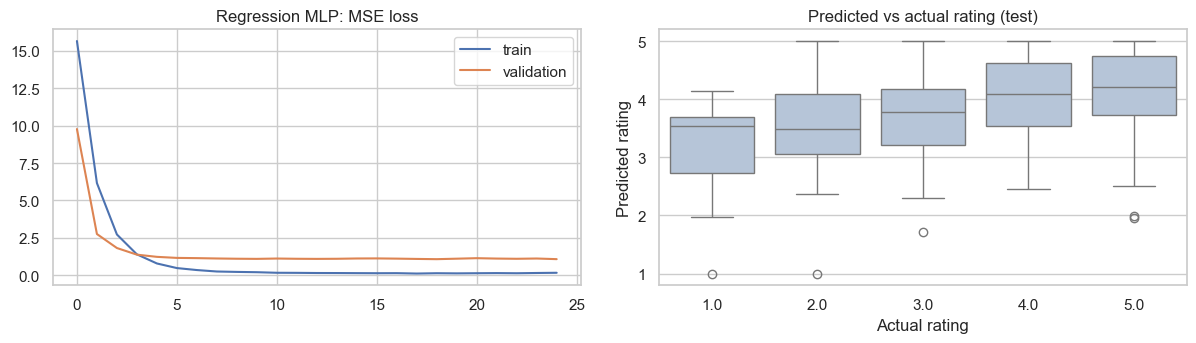

In [117]:
y_tr_reg, y_val_reg, y_test_reg = (y_tr + 1).astype("float32"), (y_val + 1).astype("float32"), (y_test + 1).astype("float32")

tf.keras.utils.set_random_seed(SEED)
reg = keras.Sequential([
    layers.Input(shape=(X_tr.shape[1],)),
    layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(1e-4)),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dense(1),                                   # linear output for a numeric target
])
reg.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
reg_hist = reg.fit(X_tr, y_tr_reg, validation_data=(X_val, y_val_reg), epochs=80, batch_size=32, verbose=0,
                   callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)])

pred_reg = np.clip(reg.predict(X_test, verbose=0).ravel(), 1, 5)
baseline_pred = np.full_like(y_test_reg, y_tr_reg.mean())
reg_table = pd.DataFrame({
    "MLP regression": [mean_absolute_error(y_test_reg, pred_reg), np.sqrt(mean_squared_error(y_test_reg, pred_reg)), r2_score(y_test_reg, pred_reg)],
    "Baseline: predict training mean": [mean_absolute_error(y_test_reg, baseline_pred), np.sqrt(mean_squared_error(y_test_reg, baseline_pred)), r2_score(y_test_reg, baseline_pred)],
}, index=["MAE (stars)", "RMSE (stars)", "R²"]).round(3)
display(reg_table)

rounded = np.rint(pred_reg).astype(int) - 1
print("Rounded regression predictions as classes ->", {k: round(v, 3) for k, v in evaluate(y_test, rounded).items()})

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(reg_hist.history["loss"], label="train"); ax[0].plot(reg_hist.history["val_loss"], label="validation")
ax[0].set_title("Regression MLP: MSE loss"); ax[0].legend()
sns.boxplot(x=y_test_reg, y=pred_reg, ax=ax[1], color="lightsteelblue")
ax[1].set_xlabel("Actual rating"); ax[1].set_ylabel("Predicted rating"); ax[1].set_title("Predicted vs actual rating (test)")
plt.tight_layout(); plt.show()

### Regression MLP: Interpretation

- **Error vs baseline:** the MLP has MAE 0.958 and RMSE 1.233, slightly better than predicting the training mean (1.010 and 1.274). That is an improvement of only about 0.05 stars.
- **R²:** 0.064, so the model explains only about 6% of the variation in ratings. The baseline is 0 by definition.
- **Rounded to classes:** accuracy is 0.315 and macro-F1 is 0.218, which is poor, though 80% of predictions are within one star of the true rating.
- **Training curves:** training loss drops close to zero while validation loss stays higher and flat, which is a sign of overfitting.
- **Boxplot:** predictions rise from about 3.5 for 1-star reviews to about 4.2 for 5-star reviews. The direction is right, but the predictions are squeezed toward the middle and the boxes overlap heavily (regression to the mean).

**Takeaway:** the text carries some signal about the rating, but a regression MLP on TF-IDF with about 680 training reviews predicts it only weakly. A numeric target does not solve the problem, so better features such as word embeddings or more data would be needed.

Selected model: D  256-64, dropout, RMSprop

              precision    recall  f1-score   support

      1 star       0.33      0.41      0.37        17
      2 star       0.00      0.00      0.00        10
      3 star       0.18      0.16      0.17        19
      4 star       0.30      0.29      0.29        38
      5 star       0.67      0.70      0.68       116

    accuracy                           0.51       200
   macro avg       0.30      0.31      0.30       200
weighted avg       0.49      0.51      0.50       200



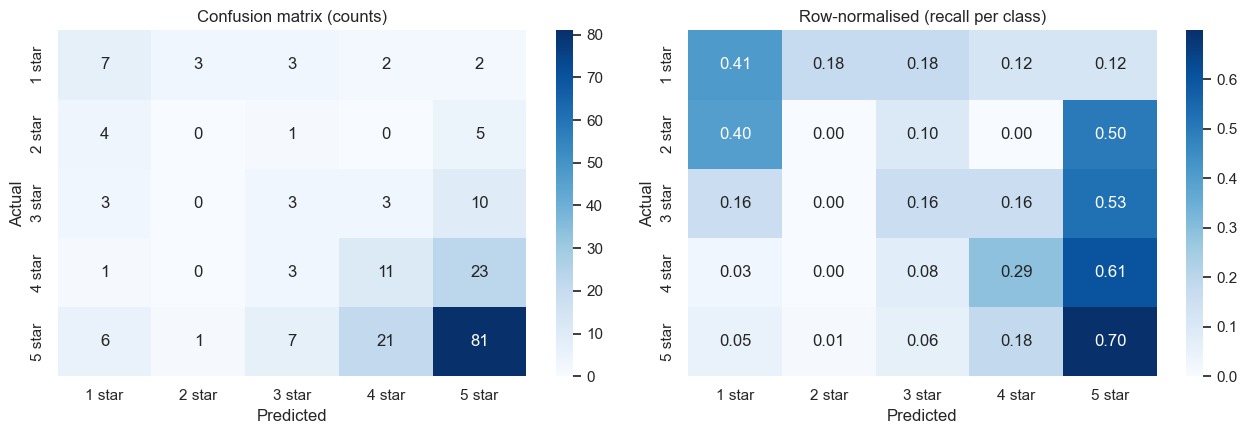

Accuracy: train = 0.973 | val = 0.567 | test = 0.51


In [123]:
best_model = trained[best_name]
y_pred = predict_classes(best_model, X_test)

print(f"Selected model: {best_name}\n")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=range(5))
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[0])
ax[0].set_title("Confusion matrix (counts)"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1])
ax[1].set_title("Row-normalised (recall per class)"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Actual")
plt.tight_layout(); plt.show()

print("Accuracy: train =", round(accuracy_score(y_tr, predict_classes(best_model, X_tr)), 3),
      "| val =", round(accuracy_score(y_val, predict_classes(best_model, X_val)), 3),
      "| test =", round(accuracy_score(y_test, y_pred), 3))

final_eval = evaluate(y_test, y_pred)
results.append({"model": f"Keras MLP – {best_name}",
                **{f"val_{k}": v for k, v in evaluate(y_val, predict_classes(best_model, X_val)).items()},
                **{f"test_{k}": v for k, v in final_eval.items()}})

### Keras MLP: Final Evaluation Interpretation

- **Overall:** accuracy is 0.51 and macro-F1 is 0.30 on 200 test reviews.
- **5 star:** recognised best (81 of 116 correct, recall 0.70).
- **4 star:** often predicted as 5 star (23 of 38), so recall is only 0.29.
- **1 star:** fairly good recall (0.41) thanks to class weights, but 2- and 3-star reviews are often confused with 5 star.
- **2 star:** never predicted correctly (recall 0.00). There are only 10 test reviews, so this is partly noise, but it shows how hard the rarest class is.
- **Overfitting:** training accuracy is 0.97 while validation is 0.57 and test is 0.51, a large gap. The model memorises the training reviews.
- **Pattern:** most errors are into the neighbouring rating or the majority class (5 star). The star scale is ordinal and the classes are imbalanced.



## Second framework: the same MLP in PyTorch

In [131]:
#!pip install torch

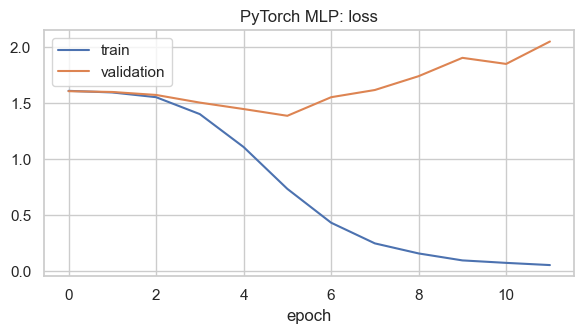

              precision    recall  f1-score   support

      1 star       0.33      0.18      0.23        17
      2 star       0.10      0.20      0.13        10
      3 star       0.16      0.21      0.18        19
      4 star       0.32      0.26      0.29        38
      5 star       0.70      0.69      0.69       116

    accuracy                           0.49       200
   macro avg       0.32      0.31      0.31       200
weighted avg       0.51      0.49      0.50       200



In [124]:
try:
    import torch, torch.nn as nn
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False
    print("PyTorch is not installed - skip this section (pip install torch) or leave it out.")

if HAS_TORCH:
    torch.manual_seed(SEED)
    Xt_tr, yt_tr = torch.tensor(X_tr), torch.tensor(y_tr, dtype=torch.long)
    Xt_val, yt_val = torch.tensor(X_val), torch.tensor(y_val, dtype=torch.long)
    Xt_test = torch.tensor(X_test)

    pt_model = nn.Sequential(
        nn.Linear(X_tr.shape[1], 256), nn.ReLU(), nn.Dropout(0.5),
        nn.Linear(256, 64), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(64, 5),                                  # raw logits; softmax is inside the loss
    )
    loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(cw, dtype=torch.float32))
    optimizer = torch.optim.Adam(pt_model.parameters(), lr=1e-3, weight_decay=1e-4)

    best_val, best_state, patience, wait = float("inf"), None, 6, 0
    train_losses, val_losses = [], []
    for epoch in range(80):
        pt_model.train()
        perm = torch.randperm(len(Xt_tr))
        epoch_loss = 0.0
        for i in range(0, len(perm), 32):
            idx = perm[i:i + 32]
            optimizer.zero_grad()
            loss = loss_fn(pt_model(Xt_tr[idx]), yt_tr[idx])
            loss.backward(); optimizer.step()
            epoch_loss += loss.item() * len(idx)
        pt_model.eval()
        with torch.no_grad():
            v = loss_fn(pt_model(Xt_val), yt_val).item()
        train_losses.append(epoch_loss / len(perm)); val_losses.append(v)
        if v < best_val:
            best_val, best_state, wait = v, copy.deepcopy(pt_model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    pt_model.load_state_dict(best_state); pt_model.eval()

    with torch.no_grad():
        pt_val_pred = pt_model(Xt_val).argmax(1).numpy()
        pt_test_pred = pt_model(Xt_test).argmax(1).numpy()

    plt.figure(figsize=(6, 3.5))
    plt.plot(train_losses, label="train"); plt.plot(val_losses, label="validation")
    plt.title("PyTorch MLP: loss"); plt.xlabel("epoch"); plt.legend(); plt.tight_layout(); plt.show()

    print(classification_report(y_test, pt_test_pred, target_names=CLASS_NAMES, zero_division=0))
    results.append({"model": "PyTorch MLP (256-64, dropout, Adam)",
                    **{f"val_{k}": v for k, v in evaluate(y_val, pt_val_pred).items()},
                    **{f"test_{k}": v for k, v in evaluate(y_test, pt_test_pred).items()}})

### PyTorch MLP: Interpretation

- **Loss curves:** training loss falls toward zero, while validation loss reaches its lowest point at about epoch 5 (about 1.4) and then rises. This is overfitting, the same pattern as the Keras model. Early stopping restored the weights from about epoch 5.
- **Overall performance:** accuracy is 0.49 and macro-F1 is 0.31 on 200 test reviews. The weighted F1 (0.50) is higher than the macro-F1 because the large 5-star class does well.
- **By class:**
  - **5 star:** best, with precision 0.70, recall 0.69 and F1 0.69. It has the most training examples.
  - **4 star:** F1 0.29.
  - **1 star:** F1 0.23.
  - **3 star:** F1 0.18.
  - **2 star:** worst, with F1 0.13. It has only 10 test reviews, so this number is very noisy.
- **Class weights:** they raised recall on the rare classes, but precision for those classes is low (0.10 to 0.33), so the model often guesses them wrongly.

**Takeaway:** PyTorch gives results similar to Keras. Both frameworks overfit this small dataset and struggle with the rare 1-3 star ratings, which shows the limit comes from the data (about 680 training reviews), not the framework.

In [125]:
def probe(texts_tr, texts_val, texts_test, y_tr_, y_val_, y_test_, label):
    vec = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    A, B, C = vec.fit_transform(texts_tr), vec.transform(texts_val), vec.transform(texts_test)
    clf = LogisticRegression(max_iter=2000, class_weight="balanced").fit(A, y_tr_)
    return {"setup": label,
            "val_macro_F1": f1_score(y_val_, clf.predict(B), average="macro"),
            "test_acc": accuracy_score(y_test_, clf.predict(C)),
            "test_macro_F1": f1_score(y_test_, clf.predict(C), average="macro")}

summary_clean = df["review_summary"].apply(lambda t: " ".join(preprocess_text(t)))
combined = df["clean_text"] + " " + summary_clean
tr_i, va_i, te_i = X_tr_txt.index, X_val_txt.index, X_test_txt.index

rows = [
    probe(df.loc[tr_i, "clean_text"], df.loc[va_i, "clean_text"], df.loc[te_i, "clean_text"], y_tr, y_val, y_test, "5-class, review text only"),
    probe(combined.loc[tr_i], combined.loc[va_i], combined.loc[te_i], y_tr, y_val, y_test, "5-class, text + summary"),
]
sent = df["sentiment_label"]
rows.append(probe(df.loc[tr_i, "clean_text"], df.loc[va_i, "clean_text"], df.loc[te_i, "clean_text"],
                  sent.loc[tr_i], sent.loc[va_i], sent.loc[te_i], "3-class sentiment (neg/neu/pos), text only"))
display(pd.DataFrame(rows).set_index("setup").round(3))

,val_macro_F1,test_acc,test_macro_F1
setup,,,
"5-class, review text only",0.348,0.580,0.384
"5-class, text + summary",0.341,0.555,0.349
"3-class sentiment (neg/neu/pos), text only",0.469,0.800,0.575


## Final model comparison

,val_accuracy,val_macro_F1,test_accuracy,test_macro_F1,test_within_1_star
model,,,,,
Baseline: always predict 5 star,0.583,0.147,0.580,0.147,0.770
Baseline: logistic regression (balanced),0.567,0.348,0.580,0.384,0.820
"PyTorch MLP (256-64, dropout, Adam)",0.542,0.400,0.495,0.306,0.795
"Keras MLP – D 256-64, dropout, RMSprop",0.567,0.353,0.510,0.302,0.800
"PyTorch MLP (256-64, dropout, Adam)",0.542,0.400,0.495,0.306,0.795


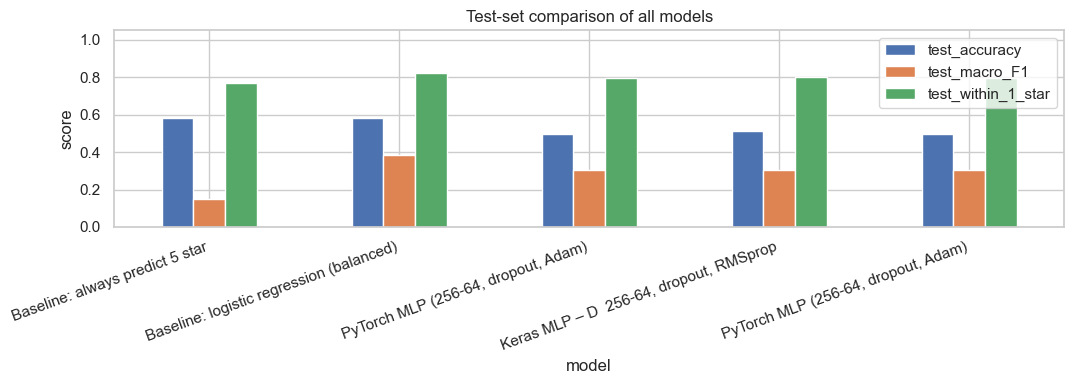

In [126]:
final_table = pd.DataFrame(results).set_index("model")
display(final_table[["val_accuracy", "val_macro_F1", "test_accuracy", "test_macro_F1", "test_within_1_star"]].round(3))

ax = final_table[["test_accuracy", "test_macro_F1", "test_within_1_star"]].plot(kind="bar", figsize=(11, 4))
ax.set_title("Test-set comparison of all models"); ax.set_ylabel("score"); ax.set_ylim(0, 1.05)
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

### Final Model Comparison: Interpretation

| Model | Accuracy | Macro-F1 | Within ±1 star |
|---|---|---|---|
| Always predict 5 star | ~0.58 | ~0.14 | ~0.77 |
| Logistic regression (balanced) | ~0.59 | ~0.39 | ~0.83 |
| PyTorch MLP | ~0.51 | ~0.31 | ~0.79 |

- **Accuracy is misleading:** "always predict 5 star" scores about 0.58 without learning anything, because 5-star reviews are the majority. Its macro-F1 is only about 0.14, which shows it fails on the other ratings.
- **Logistic regression is best:** it has the highest macro-F1 (about 0.39) and within-one-star score (about 0.83), so it handles the minority classes best.
- **PyTorch MLP:** it beats the majority baseline on macro-F1 (about 0.31 vs 0.14) but is below logistic regression, and its accuracy is lower than both baselines.
- **Why:** with only about 680 training reviews and 5,000 TF-IDF features, the neural network overfits, so a simpler linear model generalises as well or better.



### Part 3 Reflection



| Model | Test accuracy | Test macro-F1 | Within ±1 star |
|---|---|---|---|
| Always predict 5 star | 0.58 | 0.15 | 0.77 |
| Logistic regression (balanced) | 0.58 | 0.38 | 0.82 |
| Keras MLP (RMSprop) | 0.51 | 0.30 | 0.80 |
| PyTorch MLP | 0.50 | 0.31 | 0.80 |

- **Accuracy is misleading:** "always predict 5 star" scores 0.58 without learning anything, because 5-star reviews are the majority. Its macro-F1 is only 0.15, which shows it ignores the other ratings.
- **Logistic regression is best:** it has the highest macro-F1 (0.38) and within-one-star score (0.82), so it handles the rare classes best.
- **Both neural networks beat the majority baseline** on macro-F1 (0.30-0.31 vs 0.15), but neither beats logistic regression, and their accuracy is lower than both baselines.
- **Keras and PyTorch agree**, so the limit comes from the data, not the framework.
- **Why:** with only about 680 training reviews and 5,000 TF-IDF features, the networks overfit (training accuracy 0.97 vs test 0.51), so a simpler linear model generalises as well or better.

**Takeaway:** on this small, imbalanced dataset a neural network is not better than a simple baseline. The most useful improvement was merging ratings into three sentiment classes (test accuracy 0.80, macro-F1 0.575).



